In [264]:
import json
import numpy as np
import sys
import os
import pandas as pd 


In [280]:

sys.modules.pop('read_json', None)
from read_json import average_time_size, pop_time_size_stairway,pop_time_size, pop_time_size_Phlash, pop_average_time_size, pop_time_size_tskit,pop_time_size_Relate,pop_time_size_SMCpp,pop_average_sampling_time_size
sys.modules.pop('plot_code', None)
from plot_code import plot_multi_results,plot_single_results,plot_single_results_with_CI,plot_single_results_without_CI

In [547]:
palette = ['#FFCB5B','#4DAF4A','#731A73','#D65190','#E87B1E','#0076B9','#3D505A','#0098B2']
palette_average = ['#B58B00','#037D50','#731A73','#D65190','#E87B1E','#0076B9','#3D505A','#0098B2']
import matplotlib.pyplot as plt
import seaborn as sns
import json
import numpy as np
True_time_dec=[     0,     20,    200,   2000,  20000, 200000]
True_pop_dec=[ 1000,  5000, 12500, 20000, 25000, 25000]

True_time_con=[    0,    20,   200,  2000, 20000, 200000]
True_pop_con=[20000,20000,20000,20000,20000,20000]
methods = [ "PSMC", "MSMC2", "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]

In [215]:
# combine MSMC results
import json
import sys
import argparse
from pathlib import Path

def load_json_files(paths):
    data = []
    for p in paths:
        p = Path(p)
        with open(p, "r", encoding="utf-8") as f:
            data.append( json.load(f))
    return data
def parse_key(key: str) -> tuple[str, str]:
    """
    Split 'pop1_pop1_19.final.txt' into ('pop1_pop1', '19.final.txt')
    by splitting on the LAST underscore.
    """
    pop_pair, sampling_file = key.rsplit("_", 1)
    return pop_pair, sampling_file

def combine(data: list):
    values = data
    if all(isinstance(v, dict) for v in values):
        combined = {}
        for v in values:
            for pop_replicates in v.keys():

                pop,replicate = parse_key(pop_replicates)
                if pop in combined:
                    combined[pop].update({replicate:v[pop_replicates]})
                else:
                    combined[pop]={replicate:v[pop_replicates]}
    return combined

for model in ["CON", "DEC", "CON_8MB", "DEC_8MB", "CON_SPLIT", "DEC_SPLIT","CON_SPLIT_MIG","DEC_SPLIT_MIG"]:
    for replicate in range(0,10):
        print(f"Processing {model} replicate {replicate}")
        try:
            files = [f"../../Ne_sim_json/Ne_simulation/{model}/replicate{replicate}/MSMC_sampling{i}/MSMC_results.json" for i in range(1,21)]
            data = load_json_files(files)
            result = combine(data)
            with open(f"../../Ne_sim_json/Ne_simulation/{model}/replicate{replicate}/MSMC_results.json", "w") as f:
                json.dump(result, f, indent=2)
        except Exception as e:
            print(f"Error processing {model} replicate {replicate}: {e}")
        

Processing CON replicate 0
Processing CON replicate 1
Processing CON replicate 2
Processing CON replicate 3
Processing CON replicate 4
Processing CON replicate 5
Processing CON replicate 6
Processing CON replicate 7
Processing CON replicate 8
Processing CON replicate 9
Processing DEC replicate 0
Processing DEC replicate 1
Processing DEC replicate 2
Processing DEC replicate 3
Processing DEC replicate 4
Processing DEC replicate 5
Processing DEC replicate 6
Processing DEC replicate 7
Processing DEC replicate 8
Processing DEC replicate 9
Processing CON_8MB replicate 0
Processing CON_8MB replicate 1
Processing CON_8MB replicate 2
Processing CON_8MB replicate 3
Processing CON_8MB replicate 4
Processing CON_8MB replicate 5
Processing CON_8MB replicate 6
Processing CON_8MB replicate 7
Processing CON_8MB replicate 8
Processing CON_8MB replicate 9
Processing DEC_8MB replicate 0
Processing DEC_8MB replicate 1
Processing DEC_8MB replicate 2
Processing DEC_8MB replicate 3
Processing DEC_8MB replica

# DEC plot repilcate


Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC/replicate0', '../../Ne_sim_json/Ne_simulation/DEC/replicate1', '../../Ne_sim_json/Ne_simulation/DEC/replicate2', '../../Ne_sim_json/Ne_simulation/DEC/replicate3', '../../Ne_sim_json/Ne_simulation/DEC/replicate4', '../../Ne_sim_json/Ne_simulation/DEC/replicate5', '../../Ne_sim_json/Ne_simulation/DEC/replicate6', '../../Ne_sim_json/Ne_simulation/DEC/replicate7', '../../Ne_sim_json/Ne_simulation/DEC/replicate8', '../../Ne_sim_json/Ne_simulation/DEC/replicate9']
Plotting PSMC..0
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Plotting MSMC2..1
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Plotting SMC++..2
Index max time: 101
Index max time: 101
Index

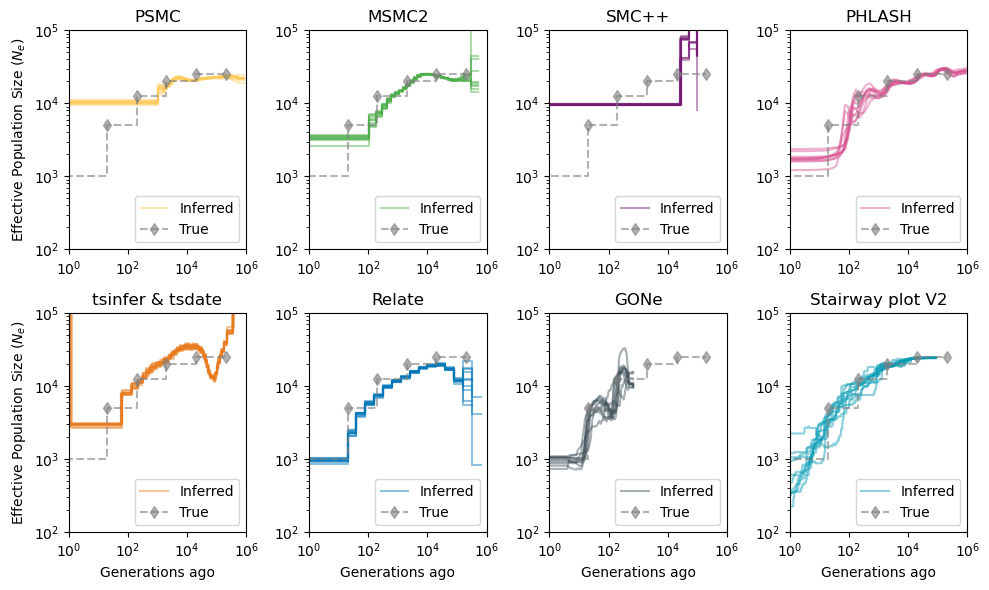

In [217]:

import glob

fig, axs = plt.subplots(2, 4, figsize=(10, 6))

base_dir = "../../Ne_sim_json/Ne_simulation/DEC"
replicate_dirs = sorted(glob.glob(os.path.join(base_dir, "replicate*")))
print(f"Found {len(replicate_dirs)} replicates: {replicate_dirs}")

filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]


def dedup_legend(ax):
    """Keep only the first occurrence of each label."""
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(), loc='lower right')

for i, (method, file) in enumerate(zip(methods, filenames)):
    ax = axs[i // 4, i % 4]
    print(f"Plotting {method}..{i}")

    for rep_idx, rep_dir in enumerate(replicate_dirs):
        # Only label the first replicate's line so the legend isn't repeated
        show_label = (rep_idx == 0)
        alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

        input_dir = rep_dir

        if method in ('MSMC2', 'PSMC'):
            pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                os.path.join(input_dir, file))
            plot_single_results(
                ax,average_times[0], median_sizes[0], 'Inferred' if show_label else None,
                palette[i], '-', max_time=1e+6, alpha=alpha
            )

        elif method == 'Stairway plot V2':
            pop_list, times, sizes = pop_time_size_stairway(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax,times[0], sizes[0][0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

        elif method == 'PHLASH':
            pop_list, times, sizes = pop_time_size_Phlash(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax,times[0], sizes[0][0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

        else:
            pop_list, times, sizes = pop_time_size(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax, times[0], sizes[0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

    ax.set_title(method)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 10e+5)
    ax.set_ylim(100, 1e+5)

    # True population history — plot once per subplot, not per replicate
    ax.step(True_time_dec, True_pop_dec,
             color='grey', linestyle='--', marker='d', label='True', where='post', alpha=0.6)

    dedup_legend(ax)

axs[0, 0].set_ylabel('Effective Population Size ($N_{e}$)')
axs[1, 0].set_ylabel('Effective Population Size ($N_{e}$)')
axs[1, 0].set_xlabel('Generations ago')
axs[1, 1].set_xlabel('Generations ago')
axs[1, 2].set_xlabel('Generations ago')
axs[1, 3].set_xlabel('Generations ago')
plt.tight_layout()
plt.savefig("../Figure_10_replicates/single_declining_Ne_replicates.png", dpi=1000)

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON/replicate0', '../../Ne_sim_json/Ne_simulation/CON/replicate1', '../../Ne_sim_json/Ne_simulation/CON/replicate2', '../../Ne_sim_json/Ne_simulation/CON/replicate3', '../../Ne_sim_json/Ne_simulation/CON/replicate4', '../../Ne_sim_json/Ne_simulation/CON/replicate5', '../../Ne_sim_json/Ne_simulation/CON/replicate6', '../../Ne_sim_json/Ne_simulation/CON/replicate7', '../../Ne_sim_json/Ne_simulation/CON/replicate8', '../../Ne_sim_json/Ne_simulation/CON/replicate9']
Plotting PSMC..0
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Index max time: 64
Plotting MSMC2..1
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Index max time: 32
Plotting SMC++..2
Index max time: 101
Index max time: 101
Index

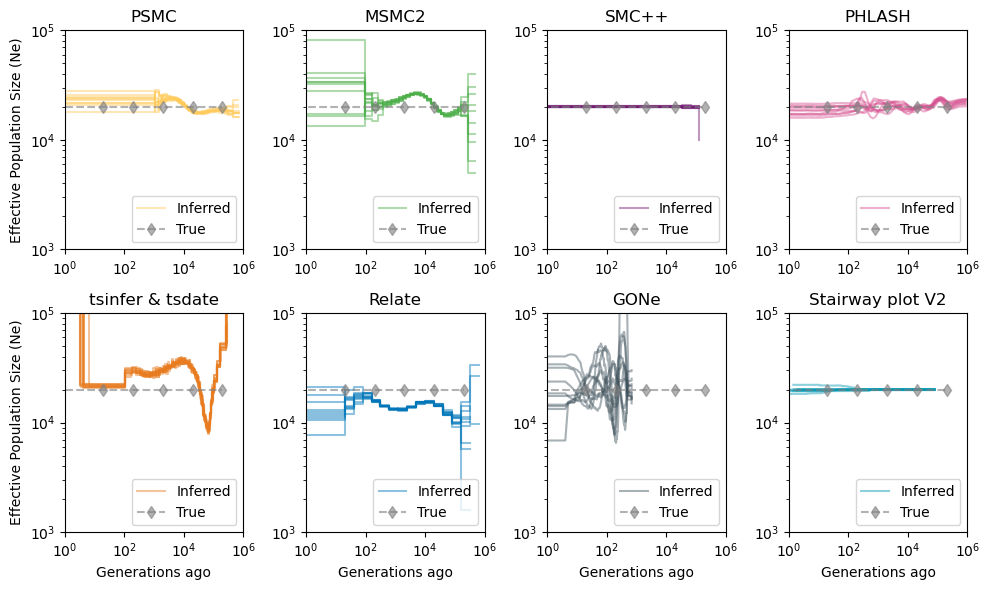

In [219]:
fig, axs = plt.subplots(2, 4, figsize=(10, 6))

base_dir = "../../Ne_sim_json/Ne_simulation/CON"
replicate_dirs = sorted(glob.glob(os.path.join(base_dir, "replicate*")))
print(f"Found {len(replicate_dirs)} replicates: {replicate_dirs}")

filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]


def dedup_legend(ax):
    """Keep only the first occurrence of each label."""
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(), loc='lower right')

for i, (method, file) in enumerate(zip(methods, filenames)):
    ax = axs[i // 4, i % 4]
    print(f"Plotting {method}..{i}")

    for rep_idx, rep_dir in enumerate(replicate_dirs):
        # Only label the first replicate's line so the legend isn't repeated
        show_label = (rep_idx == 0)
        alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

        input_dir = rep_dir

        if method in ('MSMC2', 'PSMC'):
            pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                os.path.join(input_dir, file))
            plot_single_results(
                ax,average_times[0], median_sizes[0], 'Inferred' if show_label else None,
                palette[i], '-', max_time=1e+6, alpha=alpha
            )

        elif method == 'Stairway plot V2':
            pop_list, times, sizes = pop_time_size_stairway(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax,times[0], sizes[0][0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

        elif method == 'PHLASH':
            pop_list, times, sizes = pop_time_size_Phlash(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax,times[0], sizes[0][0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

        else:
            pop_list, times, sizes = pop_time_size(os.path.join(input_dir, file))
            if len(pop_list) == 1:
                plot_single_results(
                    ax, times[0], sizes[0], 'Inferred' if show_label else None,
                    palette[i], '-', max_time=1e+6, alpha=alpha
                )

    ax.set_title(method)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 10e+5)
    ax.set_ylim(1000, 1e+5)
    # Plot true population history as a reference line
    ax.step(True_time_con, True_pop_con, 
        color='grey', linestyle='--',marker='d', label='True', alpha=0.6)
    ax.legend(loc='lower right')

    dedup_legend(ax)
# Labeling and aesthetics
axs[0,0].set_ylabel('Effective Population Size (Ne)')
axs[1,0].set_ylabel('Effective Population Size (Ne)')
axs[1,0].set_xlabel('Generations ago')
axs[1,1].set_xlabel('Generations ago')
axs[1,2].set_xlabel('Generations ago')
axs[1,3].set_xlabel('Generations ago')
plt.tight_layout()
# plt.show()
plt.savefig("../Figure_10_replicates/single_constant_Ne_replicates.png", dpi=1000)

# CON and DEC

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON/replicate0', '../../Ne_sim_json/Ne_simulation/CON/replicate1', '../../Ne_sim_json/Ne_simulation/CON/replicate2', '../../Ne_sim_json/Ne_simulation/CON/replicate3', '../../Ne_sim_json/Ne_simulation/CON/replicate4', '../../Ne_sim_json/Ne_simulation/CON/replicate5', '../../Ne_sim_json/Ne_simulation/CON/replicate6', '../../Ne_sim_json/Ne_simulation/CON/replicate7', '../../Ne_sim_json/Ne_simulation/CON/replicate8', '../../Ne_sim_json/Ne_simulation/CON/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC/replicate0', '../../Ne_sim_json/Ne_simulation/DEC/replicate1', '../../Ne_sim_json/Ne_simulation/DEC/replicate2', '../../Ne_sim_json/Ne_simulation/DEC/replicate3', '../../Ne_sim_json/Ne_simulation/DEC/replicate4', '../../Ne_sim_json/Ne_simulation/DEC/replicate5', '../../Ne_sim_json/Ne_simulation/DEC/replicate6', '../../Ne_sim_json/Ne_simulation/DEC/replicate7', '../../Ne_sim_json/Ne_simulation/DEC/replicate8', '../..

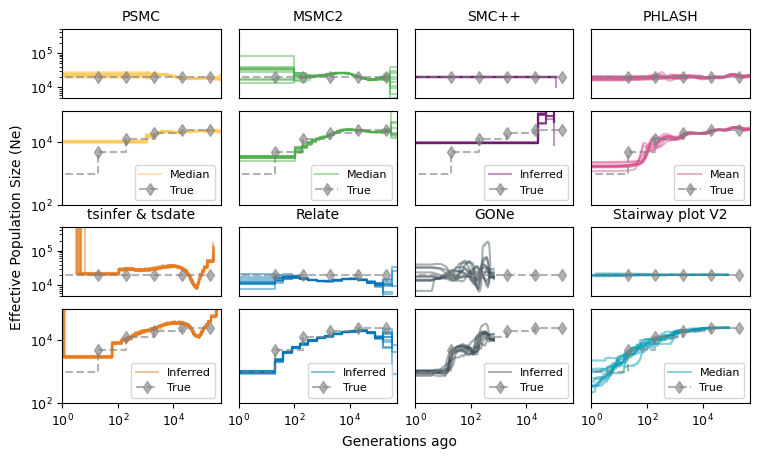

In [575]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC"

con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]

filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,4,figsize=(7.2, 4.3))

def dedup_legend(ax):
    """Keep only the first occurrence of each label."""
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(), loc='lower right',fontsize=8)
    

for i in range(4):
    for j in range(4):
        ax = axs[i, j]
        method = methods[4*(i//2)+j]
        file = filenames[4*(i//2)+j]
        color = palette[4*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                plot_single_results(
                    ax,average_times[0], median_sizes[0], 'Median' if show_label else None,
                    color , '-', max_time=1e+6, alpha=alpha
                )

            elif method == 'Stairway plot V2':
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax,times[0], sizes[0][0], 'Median' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax,times[0], sizes[0][0], 'Mean' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax, times[0], sizes[0], 'Inferred' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

        if i == 0 or i== 2:
            ax.set_title(methods[4*(i//2)+j],fontsize=10)
            ax.set_xlim(1, 5e+5)
            ax.set_ylim(5000, 5e+5)
            True_time= True_time_con
            True_pop= True_pop_con
            ax.step(True_time, True_pop, 
            color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where= 'post')
        else:

            ax.set_xlim(1, 5e+5)
            ax.set_ylim(100, 1e+5)
            True_time= True_time_dec
            True_pop= True_pop_dec
            ax.step(True_time, True_pop, 
            color='grey', linestyle='--',marker='d', label='True', alpha=0.6, where= 'post')
            
            dedup_legend(ax)
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")



# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])

axs[0,3].set_position([0.785, 0.76,0.22,0.16])
axs[1,3].set_position([0.785, 0.51,0.22,0.22])
axs[2,3].set_position([0.785, 0.3,0.22,0.16])
axs[3,3].set_position([0.785, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_CON_DEC_Model.png", dpi=300, bbox_inches='tight')

import pickle
import phlash
import numpy as np
import json
output_file = "./0"
with open(output_file + '.pkl', 'rb') as f: 
    results = pickle.load(f)
with open(output_file+'.json', "w") as f:
    times = np.array([dm.eta.t[1:] for dm in results])
    # choose a grid of points at which to evaluate the size history functions
    T = np.geomspace(times.min(), times.max(), 1000)
    Nes = np.array([dm.eta(T, Ne=True) for dm in results])
    T_Nes = {}
    for index in range(len(T)):
        Ne = Nes[:,index]
        T_Nes[T[index]] = [np.mean(Ne), np.median(Ne), np.percentile(Ne, 2.5), np.percentile(Ne, 97.5), np.percentile(Ne, 12.5), np.percentile(Ne, 87.5)]
    json.dump(T_Nes, f, indent=4)

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate0', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate1', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate2', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate3', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate4', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate5', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate6', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate7', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate8', '../../Ne_sim_json/Ne_simulation/CON_8Mb/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate3', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate4', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate5', '../../Ne_sim_json/Ne_simulation/DEC_8Mb/replicate6', '../../Ne_sim_json/Ne_simulation/DEC_8

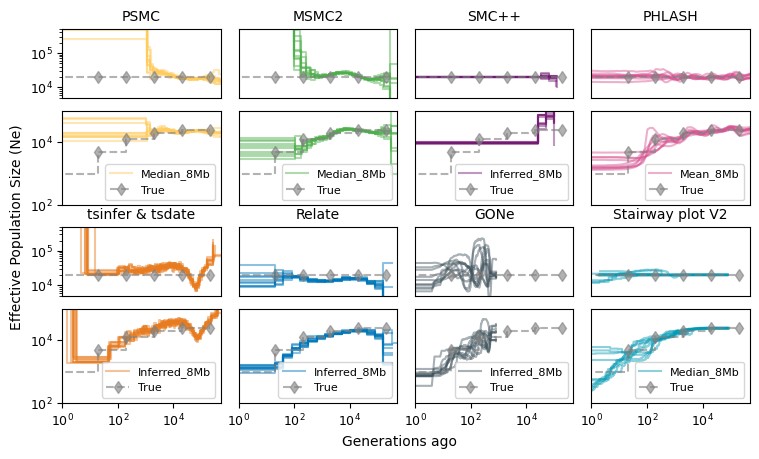

In [283]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON_8Mb"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC_8Mb"
con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]

filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,4,figsize=(7.2, 4.3))

def dedup_legend(ax):
    """Keep only the first occurrence of each label."""
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen:
            seen[l] = h
    ax.legend(seen.values(), seen.keys(), loc='lower right',fontsize=8)
    

for i in range(4):
    for j in range(4):
        ax = axs[i, j]
        method = methods[4*(i//2)+j]
        file = filenames[4*(i//2)+j]
        color = palette[4*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                plot_single_results(
                    ax,average_times[0], median_sizes[0], 'Median_8Mb' if show_label else None,
                    color , '-', max_time=1e+6, alpha=alpha
                )

            elif method == 'Stairway plot V2':
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax,times[0], sizes[0][0], 'Median_8Mb' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax,times[0], sizes[0][0], 'Mean_8Mb' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))
                if len(pop_list) == 1:
                    plot_single_results(
                        ax, times[0], sizes[0], 'Inferred_8Mb' if show_label else None,
                        color , '-', max_time=1e+6, alpha=alpha
                    )

        if i == 0 or i== 2:
            ax.set_title(methods[4*(i//2)+j],fontsize=10)
            ax.set_xlim(1, 5e+5)
            ax.set_ylim(5000, 5e+5)
            True_time= True_time_con
            True_pop= True_pop_con
            ax.step(True_time, True_pop, 
            color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where= 'post')
        else:

            ax.set_xlim(1, 5e+5)
            ax.set_ylim(100, 1e+5)
            True_time= True_time_dec
            True_pop= True_pop_dec
            ax.step(True_time, True_pop, 
            color='grey', linestyle='--',marker='d', label='True', alpha=0.6, where= 'post')
            
            dedup_legend(ax)
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")



# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])

axs[0,3].set_position([0.785, 0.76,0.22,0.16])
axs[1,3].set_position([0.785, 0.51,0.22,0.22])
axs[2,3].set_position([0.785, 0.3,0.22,0.16])
axs[3,3].set_position([0.785, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_CON_DEC_Model_8Mb.png", dpi=300, bbox_inches='tight')

In [560]:

True_time_dec12=[0, 20, 200, 2000, 20000, 200000]
True_pop_dec1=[1000, 5000, 12500, 20000, 25000, 22000]
True_pop_dec2=[200, 1200, 3000, 16000, 20000, 22000]

True_time_con12=[0, 20, 200, 2000, 20000, 200000]
True_pop_con1=[22_000,22_000,22_000,22_000,22_000,20_000]
True_pop_con2=[18000, 18000, 18000, 18000, 18000, 20000]


In [566]:
import colorsys
import matplotlib.colors as mcolors

def adjust_lightness(color, amount=1.0):
    """amount > 1 变亮，amount < 1 变暗"""
    c = mcolors.to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(*c)
    l = max(0, min(1, l * amount))
    return colorsys.hls_to_rgb(h, l, s)

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate0', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate1', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate2', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate3', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate4', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate5', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate6', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate7', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate8', '../../Ne_sim_json/Ne_simulation/CON_SPLIT/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate3', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate4', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate5', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT/replicate6', '../

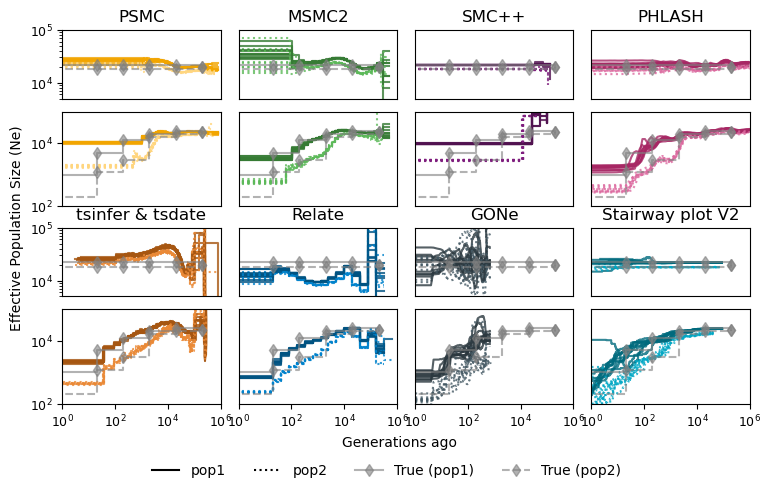

In [577]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON_SPLIT"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC_SPLIT"

con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]
dict_color_shade = {"1": 0.7, "2": 1.1}   # pop1 偏暗，pop2 偏亮（数值可调）
dict_shape = {"1": "-", "2": ":"}
pop_selected=["1","2"]
filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,4,figsize=(7.2, 4.3))


for i in range(4):
    for j in range(4):
        ax = axs[i, j]
        method = methods[4*(i//2)+j]
        file = filenames[4*(i//2)+j]
        color = palette[4*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.8 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
            elif method =="SMCpp":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir, file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir, file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir, file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))

            dic_pop={}
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index
            for pop_name,pop_index in dic_pop.items():
                pop_color = adjust_lightness(color, dict_color_shade[pop_name])
                if method in ('MSMC2', 'PSMC'):
                    plot_single_results(
                        ax,average_times[pop_index], median_sizes[pop_index], f'pop{pop_name}-Median' if show_label else None,
                        pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                    )
                elif method == 'Stairway plot V2':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Median' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                elif method == 'PHLASH':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Mean' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                else:
                    plot_single_results(
                            ax, times[pop_index], sizes[pop_index], f'pop{pop_name}-Inferred' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
            
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if i == 1 or i == 3:
            # ax.legend(loc='lower right')
            pass
        if i == 0 or i== 2:
            ax.set_title(methods[4*(i//2)+j])
            ax.set_xlim(1, 10e+5)
            ax.set_ylim(5000, 1e+5)
            ax.step(True_time_con, True_pop_con1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
        else:
            ax.set_xlim(1, 10e+5)
            # ax.set_xlim(1, 20e+2)
            ax.set_ylim(100, 1e+5)
            ax.step(True_time_dec, True_pop_dec1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")


from matplotlib.lines import Line2D

# 手动构造图例条目（不依赖具体某个 method 的颜色，用黑色代表线型含义）
custom_handles = [
    Line2D([0], [0], color='black', linestyle='-', label='pop1'),
    Line2D([0], [0], color='black', linestyle=':', label='pop2'),
    Line2D([0], [0], color='grey', linestyle='-', marker='d', alpha=0.6, label='True (pop1)'),
    Line2D([0], [0], color='grey', linestyle='--', marker='d', alpha=0.6, label='True (pop2)'),
]

fig.legend(handles=custom_handles, loc='lower center', 
           bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=10, frameon=False)


# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])

axs[0,3].set_position([0.785, 0.76,0.22,0.16])
axs[1,3].set_position([0.785, 0.51,0.22,0.22])
axs[2,3].set_position([0.785, 0.3,0.22,0.16])
axs[3,3].set_position([0.785, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_model_split.png", dpi=300, bbox_inches='tight')

from recent time to about 2,000 the variance increase significantly, this tend show in the Model CON very clean.

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate0', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate1', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate2', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate3', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate4', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate5', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate6', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate7', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate8', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate3', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate4', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG/replicate

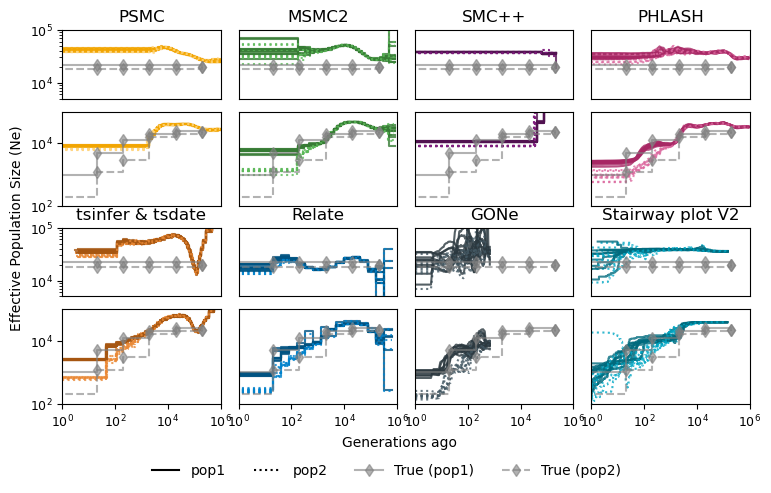

In [578]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG"

con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]
dict_color_shade = {"1": 0.7, "2": 1.1}   # pop1 偏暗，pop2 偏亮（数值可调）
dict_shape = {"1": "-", "2": ":"}
pop_selected=["1","2"]
filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,4,figsize=(7.2, 4.3))


for i in range(4):
    for j in range(4):
        ax = axs[i, j]
        method = methods[4*(i//2)+j]
        file = filenames[4*(i//2)+j]
        color = palette[4*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.8 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
            elif method =="SMCpp":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir, file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir, file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir, file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))

            dic_pop={}
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index
            for pop_name,pop_index in dic_pop.items():
                pop_color = adjust_lightness(color, dict_color_shade[pop_name])
                if method in ('MSMC2', 'PSMC'):
                    plot_single_results(
                        ax,average_times[pop_index], median_sizes[pop_index], f'pop{pop_name}-Median' if show_label else None,
                        pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                    )
                elif method == 'Stairway plot V2':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Median' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                elif method == 'PHLASH':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Mean' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                else:
                    plot_single_results(
                            ax, times[pop_index], sizes[pop_index], f'pop{pop_name}-Inferred' if show_label else None,
                            pop_color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
            
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if i == 1 or i == 3:
            # ax.legend(loc='lower right')
            pass
        if i == 0 or i== 2:
            ax.set_title(methods[4*(i//2)+j])
            ax.set_xlim(1, 10e+5)
            ax.set_ylim(5000, 1e+5)
            ax.step(True_time_con, True_pop_con1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
        else:
            ax.set_xlim(1, 10e+5)
            # ax.set_xlim(1, 20e+2)
            ax.set_ylim(100, 1e+5)
            ax.step(True_time_dec, True_pop_dec1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")


from matplotlib.lines import Line2D

# 手动构造图例条目（不依赖具体某个 method 的颜色，用黑色代表线型含义）
custom_handles = [
    Line2D([0], [0], color='black', linestyle='-', label='pop1'),
    Line2D([0], [0], color='black', linestyle=':', label='pop2'),
    Line2D([0], [0], color='grey', linestyle='-', marker='d', alpha=0.6, label='True (pop1)'),
    Line2D([0], [0], color='grey', linestyle='--', marker='d', alpha=0.6, label='True (pop2)'),
]

fig.legend(handles=custom_handles, loc='lower center', 
           bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=10, frameon=False)


# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])

axs[0,3].set_position([0.785, 0.76,0.22,0.16])
axs[1,3].set_position([0.785, 0.51,0.22,0.22])
axs[2,3].set_position([0.785, 0.3,0.22,0.16])
axs[3,3].set_position([0.785, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_model_split_mig.png", dpi=300, bbox_inches='tight')

# pop structure will affect results?

In [589]:
True_time_dec12=[0, 20, 200, 2000, 20000, 200000]
True_pop_dec1=[1000, 5000, 12500, 20000, 25000, 22000]
True_pop_dec2=[200, 1200, 3000, 16000, 20000, 22000]
True_pop_dec12=[1200, 6200, 15500,36000,45000, 22000]

True_time_con12=[0, 20, 200, 2000, 20000, 200000]
True_pop_con1=[22_000,22_000,22_000,22_000,22_000,20_000]
True_pop_con2=[18000, 18000, 18000, 18000, 18000, 20000]
True_pop_con12=[40_000,40_000,40_000,40_000,40_000,20_000]
palette = ['#731A73','#D65190','#E87B1E','#0076B9','#3D505A','#0098B2']

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate0', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate1', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate2', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate3', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate4', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate5', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate6', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate7', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate8', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate3', '../../Ne_sim_json/Ne_simulation

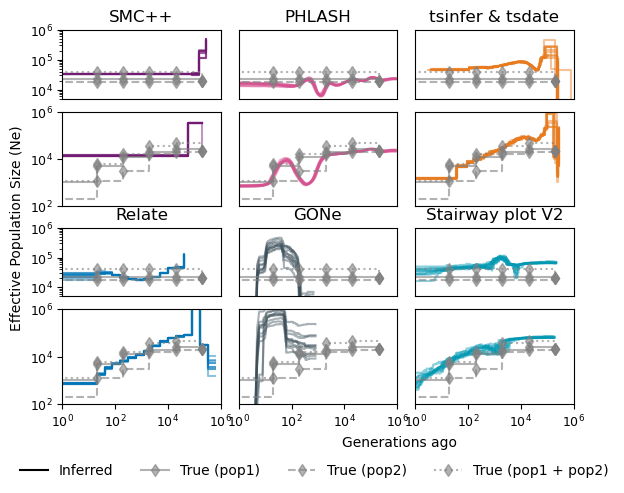

In [596]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure"

con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]
dict_shape = {"1": "-", "2": ":"}
pop_selected=["1"]
filenames = [
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,3,figsize=(7.2, 4.3))
methods = ["SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]

for i in range(4):
    for j in range(3):
        ax = axs[i, j]
        method = methods[3*(i//2)+j]
        file = filenames[3*(i//2)+j]
        color = palette[3*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
            elif method =="SMCpp":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir, file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir, file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir, file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))

            dic_pop={}
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index
            for pop_name,pop_index in dic_pop.items():
                if method in ('MSMC2', 'PSMC'):
                    plot_single_results(
                        ax,average_times[pop_index], median_sizes[pop_index], f'pop{pop_name}-Median' if show_label else None,
                        color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                    )
                elif method == 'Stairway plot V2':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Median' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                elif method == 'PHLASH':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Mean' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                else:
                    plot_single_results(
                            ax, times[pop_index], sizes[pop_index], f'pop{pop_name}-Inferred' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
            
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if i == 1 or i == 3:
            # ax.legend(loc='lower right')
            pass
        if i == 0 or i== 2:
            ax.set_title(methods[3*(i//2)+j])
            ax.set_xlim(1, 10e+5)
            ax.set_ylim(5000, 1e+6)
            ax.step(True_time_con, True_pop_con1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con12, 
                color='grey', linestyle=':',marker='d', label='True', alpha=0.6,where='post')
        else:
            ax.set_xlim(1, 10e+5)
            # ax.set_xlim(1, 20e+2)
            ax.set_ylim(100, 1e+6)
            ax.step(True_time_dec, True_pop_dec1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec12, 
                color='grey', linestyle=':',marker='d', label='True', alpha=0.6,where='post')
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")


from matplotlib.lines import Line2D

# 手动构造图例条目（不依赖具体某个 method 的颜色，用黑色代表线型含义）
custom_handles = [
    Line2D([0], [0], color='black', linestyle='-', label='Inferred'),
    Line2D([0], [0], color='grey', linestyle='-', marker='d', alpha=0.6, label='True (pop1)'),
    Line2D([0], [0], color='grey', linestyle='--', marker='d', alpha=0.6, label='True (pop2)'),
    Line2D([0], [0], color='grey', linestyle=':', marker='d', alpha=0.6, label='True (pop1 + pop2)')
]

fig.legend(handles=custom_handles, loc='lower center', 
           bbox_to_anchor=(0.4, -0.15), ncol=4, fontsize=10, frameon=False)


# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_pop_structure_split.png", dpi=300, bbox_inches='tight')

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate0', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate1', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate2', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate3', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate4', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate5', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate6', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate7', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate8', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG

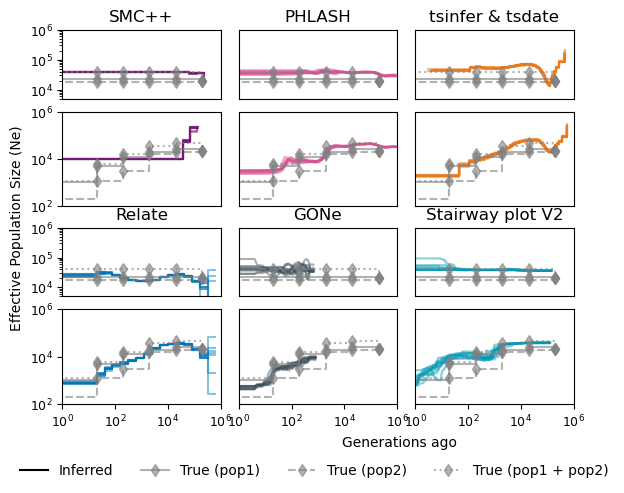

In [597]:
input_dir_con = "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure"
input_dir_dec = "../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure"

con_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_con, "replicate*")))
print(f"Found {len(con_replicate_dirs)} replicates: {con_replicate_dirs}")

dec_replicate_dirs = sorted(glob.glob(os.path.join(input_dir_dec, "replicate*")))
print(f"Found {len(dec_replicate_dirs)} replicates: {dec_replicate_dirs}")

list_dir = [con_replicate_dirs, dec_replicate_dirs]
dict_shape = {"1": "-", "2": ":"}
pop_selected=["1"]
filenames = [
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
fig,axs = plt.subplots(4,3,figsize=(7.2, 4.3))
methods = ["SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]

for i in range(4):
    for j in range(3):
        ax = axs[i, j]
        method = methods[3*(i//2)+j]
        file = filenames[3*(i//2)+j]
        color = palette[3*(i//2)+j]
        input_dir = i%2
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            show_label = (rep_idx == 0)
            alpha = 0.45 if len(replicate_dirs) > 1 else 1.0

            if method in ('MSMC2', 'PSMC'):
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(
                    os.path.join(rep_dir, file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir, file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir, file))
            elif method =="SMCpp":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir, file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir, file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir, file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir, file))

            dic_pop={}
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index
            for pop_name,pop_index in dic_pop.items():
                if method in ('MSMC2', 'PSMC'):
                    plot_single_results(
                        ax,average_times[pop_index], median_sizes[pop_index], f'pop{pop_name}-Median' if show_label else None,
                        color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                    )
                elif method == 'Stairway plot V2':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Median' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                elif method == 'PHLASH':
                    plot_single_results(
                            ax,times[pop_index], sizes[pop_index][0], f'pop{pop_name}-Mean' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
                else:
                    plot_single_results(
                            ax, times[pop_index], sizes[pop_index], f'pop{pop_name}-Inferred' if show_label else None,
                            color, dict_shape[pop_name], max_time=1e+6, alpha=alpha
                        )
            
        ax.tick_params(axis='x', labelsize=9) 
        ax.tick_params(axis='y', labelsize=9)
        if i == 1 or i == 3:
            # ax.legend(loc='lower right')
            pass
        if i == 0 or i== 2:
            ax.set_title(methods[3*(i//2)+j])
            ax.set_xlim(1, 10e+5)
            ax.set_ylim(5000, 1e+6)
            ax.step(True_time_con, True_pop_con1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_con, True_pop_con12, 
                color='grey', linestyle=':',marker='d', label='True', alpha=0.6,where='post')
        else:
            ax.set_xlim(1, 10e+5)
            # ax.set_xlim(1, 20e+2)
            ax.set_ylim(100, 1e+6)
            ax.step(True_time_dec, True_pop_dec1, 
                color='grey', linestyle='-',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec2, 
                color='grey', linestyle='--',marker='d', label='True', alpha=0.6,where='post')
            ax.step(True_time_dec, True_pop_dec12, 
                color='grey', linestyle=':',marker='d', label='True', alpha=0.6,where='post')
        if j!=0:
            ax.get_yaxis().set_visible(False)
        if i!=3:
            ax.get_xaxis().set_visible(False)
        ax.set_xscale("log")
        ax.set_yscale("log")


from matplotlib.lines import Line2D

# 手动构造图例条目（不依赖具体某个 method 的颜色，用黑色代表线型含义）
custom_handles = [
    Line2D([0], [0], color='black', linestyle='-', label='Inferred'),
    Line2D([0], [0], color='grey', linestyle='-', marker='d', alpha=0.6, label='True (pop1)'),
    Line2D([0], [0], color='grey', linestyle='--', marker='d', alpha=0.6, label='True (pop2)'),
    Line2D([0], [0], color='grey', linestyle=':', marker='d', alpha=0.6, label='True (pop1 + pop2)')
]

fig.legend(handles=custom_handles, loc='lower center', 
           bbox_to_anchor=(0.4, -0.15), ncol=4, fontsize=10, frameon=False)


# axs[0,0].get_yaxis().set_visible(False)
# Labeling and aesthetics
x_label = axs[3,2].set_xlabel('Generations ago', fontsize=10)
x_label.set_position((-0.1, 1))
y_label=axs[2,0].set_ylabel('Effective Population Size (Ne)',fontsize=10)
y_label.set_position((0.1, 1))
axs[0,0].set_position([0.05, 0.76,0.22,0.16])
axs[1,0].set_position([0.05, 0.51,0.22,0.22])
axs[2,0].set_position([0.05, 0.3,0.22,0.16])
axs[3,0].set_position([0.05, 0.05,0.22,0.22])

axs[0,1].set_position([0.295, 0.76,0.22,0.16])
axs[1,1].set_position([0.295, 0.51,0.22,0.22])
axs[2,1].set_position([0.295, 0.3,0.22,0.16])
axs[3,1].set_position([0.295, 0.05,0.22,0.22])

axs[0,2].set_position([0.54, 0.76,0.22,0.16])
axs[1,2].set_position([0.54, 0.51,0.22,0.22])
axs[2,2].set_position([0.54, 0.3,0.22,0.16])
axs[3,2].set_position([0.54, 0.05,0.22,0.22])
# plt.show()
plt.savefig("../Figure_10_replicates/Ne_pop_structure_split_mig.png", dpi=300, bbox_inches='tight')

GONE and Phlash, the population structure has significant impact on the results, FOR  GONE, we can see the false population expansion and contract signal, and For phlash it is a extramely drop and increasing signal.
Tskit and Relate, Staiway don't affact the the droping trend, but value....
compare the root mean squared error

In [99]:
from root_mean_squared_error import cal_rmse

# Root mean-squared error

rmse = np.sqrt(np.mean((y_true - y_pred)**2))

# replicates
mean_rmse = np.mean(rmse_array)

sd_rmse = np.std(rmse_array, ddof=1)

In [625]:
sys.modules.pop('root_mean_squared_error', None)
from root_mean_squared_error import cal_rmse
True_time_dec=[     0,     20,    200,   2000,  20000, 200000]
True_pop_dec=[ 1000,  5000, 12500, 20000, 25000, 25000]

True_time_con=[    0,    20,   200,  2000, 20000, 200000]
True_pop_con=[20000,20000,20000,20000,20000,20000]
methods = [ "PSMC", "MSMC2", "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]

True_time_dec12=[0, 20, 200, 2000, 20000, 200000]
True_pop_dec1=[1000, 5000, 12500, 20000, 25000, 22000]
True_pop_dec2=[200, 1200, 3000, 16000, 20000, 22000]
True_pop_dec12=[1200, 6200, 15500,36000,45000, 22000]

True_time_con12=[0, 20, 200, 2000, 20000, 200000]
True_pop_con1=[22_000,22_000,22_000,22_000,22_000,20_000]
True_pop_con2=[18000, 18000, 18000, 18000, 18000, 20000]
True_pop_con12=[40_000,40_000,40_000,40_000,40_000,20_000]
palette = ['#FFCB5B','#4DAF4A','#731A73','#D65190','#E87B1E','#0076B9','#3D505A','#0098B2']
palette_average = ['#B58B00','#037D50','#731A73','#D65190','#E87B1E','#0076B9','#3D505A','#0098B2']

In [626]:
# file, model, method, population, genome length, sample, total_rmse, time_series
# split_epoch = [0,20,500, 2500, 20000, 200000]
# called widow along the simulated epoch 
split_epoch = [0,20,200, 2000, 20000, 200000]
results_rmse = []
n_epochs = len(split_epoch)-1

In [627]:
list_input_dir = ["../../Ne_sim_json/Ne_simulation/CON", "../../Ne_sim_json/Ne_simulation/DEC","../../Ne_sim_json/Ne_simulation/CON_8Mb","../../Ne_sim_json/Ne_simulation/DEC_8Mb", \
    "../../Ne_sim_json/Ne_simulation/CON_SPLIT", "../../Ne_sim_json/Ne_simulation/DEC_SPLIT", \
        "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG","../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG", ]
list_dir=[]
for input_dir in list_input_dir:
    replicate_dirs = sorted(glob.glob(os.path.join(input_dir, "replicate*")))
    print(f"Found {len(replicate_dirs)} replicates: {replicate_dirs}")
    list_dir.append(replicate_dirs)
list_time_true = [True_time_con, True_time_dec,True_time_con, True_time_dec, \
    True_time_con12, True_time_dec12,True_time_con12, True_time_dec12]
dict_size_true = {"1":[True_pop_con,True_pop_dec,True_pop_con,True_pop_dec, \
    True_pop_con1,True_pop_dec1,True_pop_con1,True_pop_dec1], \
    "2": [True_pop_con,True_pop_dec,True_pop_con,True_pop_dec, \
        True_pop_con2,True_pop_dec2,True_pop_con2,True_pop_dec2]}
pop_selected=["1","2"]

filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
label_model=["CON Model","DEC Model","CON Model","DEC Model", \
    "CON SPLIT Model","DEC SPLIT Model","CON SPLIT MIG Model","DEC SPLIT MIG Model"]
contig_length = ["80MB","80MB","8MB","8MB","80MB","80MB","80MB","80MB"]
dic_pop={}

for input_dir in range(len(list_input_dir)):
    for j_idx in range(8):
        method = methods[j_idx]
        file = filenames[j_idx]
        color = palette[j_idx]
        print(method)
        dic_pop_values={}
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            if method == 'PSMC':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
                # label = pop+"_"+"Median"
            elif method == 'MSMC2':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir,file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir,file))
            elif method =="SMC++":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir,file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir,file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir,file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir,file))
            
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index

            for pop_name,pop_index in dic_pop.items():
                if method == "PHLASH" or method == "Stairway plot V2":
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index][0],list_time_true[input_dir],dict_size_true[pop_name][input_dir],split_epoch)       
                else:
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index],list_time_true[input_dir],dict_size_true[pop_name][input_dir],split_epoch)  
                # print(list_dir[input_dir],method,pop_name,rmse_epoch,rmse)  
                if pop_name in dic_pop_values:
                    dic_pop_values[pop_name].append([rmse_epoch,rmse])
                else:
                    dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
        for pop_name,values in dic_pop_values.items():
            rmse_epochs = [[] for _ in range(n_epochs)]
            rmse = []
            for rep_results in values:
                for epoch in range(n_epochs):
                    rmse_epochs[epoch].append(rep_results[0][epoch])
                rmse.append(rep_results[1])
            rmse_average = np.mean(rmse)
            rmse_sd = np.std(rmse, ddof=1)

            rmse_epoch_average = []
            rmse_epoch_sd = []
            for rmse_epoch in rmse_epochs:
                rmse_epoch_average.append(np.mean(rmse_epoch))
                rmse_epoch_sd.append(np.std(rmse_epoch, ddof=1))
            print(input_dir)
            results_rmse.append([list_dir[input_dir],label_model[input_dir],method,pop_name,contig_length[input_dir],100,rmse_average,rmse_sd,rmse_epoch_average,rmse_epoch_sd]) 

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON/replicate0', '../../Ne_sim_json/Ne_simulation/CON/replicate1', '../../Ne_sim_json/Ne_simulation/CON/replicate2', '../../Ne_sim_json/Ne_simulation/CON/replicate3', '../../Ne_sim_json/Ne_simulation/CON/replicate4', '../../Ne_sim_json/Ne_simulation/CON/replicate5', '../../Ne_sim_json/Ne_simulation/CON/replicate6', '../../Ne_sim_json/Ne_simulation/CON/replicate7', '../../Ne_sim_json/Ne_simulation/CON/replicate8', '../../Ne_sim_json/Ne_simulation/CON/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC/replicate0', '../../Ne_sim_json/Ne_simulation/DEC/replicate1', '../../Ne_sim_json/Ne_simulation/DEC/replicate2', '../../Ne_sim_json/Ne_simulation/DEC/replicate3', '../../Ne_sim_json/Ne_simulation/DEC/replicate4', '../../Ne_sim_json/Ne_simulation/DEC/replicate5', '../../Ne_sim_json/Ne_simulation/DEC/replicate6', '../../Ne_sim_json/Ne_simulation/DEC/replicate7', '../../Ne_sim_json/Ne_simulation/DEC/replicate8', '../..

/Users/s2587593/opt/anaconda3/envs/common/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/s2587593/opt/anaconda3/envs/common/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


handle time-point
handle time-point
handle time-point
0
PSMC
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
1
MSMC2
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
1
SMC++
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
handle time-period
1
PHLASH
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
handle time-point
1
tsinfer & tsdate
1
handle time-period
1
handle time-period
1
handle time-period
1
handle time-period
1
handle time-period
1
handle time-period
1
handle time-perio

In [628]:
list_input_dir = ["../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure", "../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure", \
    "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure","../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure", ]
list_dir=[]
for input_dir in list_input_dir:
    replicate_dirs = sorted(glob.glob(os.path.join(input_dir, "replicate*")))
    print(f"Found {len(replicate_dirs)} replicates: {replicate_dirs}")
    list_dir.append(replicate_dirs)

list_time_true = [True_time_con12, True_time_dec12,True_time_con12, True_time_dec12 ]
dict_size_true = {"1":[True_pop_con12,True_pop_dec12,True_pop_con12,True_pop_dec12], \
    "2": [ True_pop_con12,True_pop_dec12,True_pop_con12,True_pop_dec12]}
pop_selected=["1","2"]

filenames = [
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
methods = [ "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
label_model=[ "CON SPLIT Model (Pop Structure)","DEC SPLIT Model (Pop Structure)","CON SPLIT MIG Model (Pop Structure)","DEC SPLIT MIG Model (Pop Structure)"]
dic_pop={}
for i in range(len(list_input_dir)):
    for j in range(6):
        method = methods[j]
        file = filenames[j]
        color = palette[j]
        print(method)
        input_dir = i
        dic_pop_values={}
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            if method == 'PSMC':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
                # label = pop+"_"+"Median"
                print(times[0].shape)
                for a in all_times[0]:
                    if a[0] != 0:
                        print(a)
                print(times[0][0])
            elif method == 'MSMC2':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir,file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir,file))
            elif method =="SMC++":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir,file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir,file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir,file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir,file))
            
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index

            for pop_name,pop_index in dic_pop.items():
                if method == "PHLASH" or method == "Stairway plot V2":
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index][0],list_time_true[input_dir],dict_size_true[pop_name][input_dir],split_epoch)       
                else:
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index],list_time_true[input_dir],dict_size_true[pop_name][input_dir],split_epoch)      
                # print(list_dir[input_dir],method,pop_name,rmse_epoch,rmse)  
                if pop_name in dic_pop_values:
                    dic_pop_values[pop_name].append([rmse_epoch,rmse])
                else:
                    dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
        for pop_name,values in dic_pop_values.items():
            rmse_epochs = [[] for _ in range(n_epochs)]
            rmse = []
            for rep_results in values:
                for epoch in range(n_epochs):
                    rmse_epochs[epoch].append(rep_results[0][epoch])
                rmse.append(rep_results[1])
            rmse_average = np.mean(rmse)
            rmse_sd = np.std(rmse, ddof=1)

            rmse_epoch_average = []
            rmse_epoch_sd = []
            for rmse_epoch in rmse_epochs:
                rmse_epoch_average.append(np.mean(rmse_epoch))
                rmse_epoch_sd.append(np.std(rmse_epoch, ddof=1))
            print(input_dir)
            results_rmse.append([list_dir[input_dir],label_model[input_dir],method,"1+2","80MB",200,rmse_average,rmse_sd,rmse_epoch_average,rmse_epoch_sd]) 

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate0', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate1', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate2', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate3', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate4', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate5', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate6', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate7', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate8', '../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure/replicate3', '../../Ne_sim_json/Ne_simulation

In [629]:


list_input_dir = ["../../Ne_sim_json/Ne_simulation/CON_5", "../../Ne_sim_json/Ne_simulation/DEC_5", \
    "../../Ne_sim_json/Ne_simulation/CON_20", "../../Ne_sim_json/Ne_simulation/DEC_20", \
          "../../Ne_sim_json/Ne_simulation/CON_40", "../../Ne_sim_json/Ne_simulation/DEC_40", \
            "../../Ne_sim_json/Ne_simulation/CON_60", "../../Ne_sim_json/Ne_simulation/DEC_60", \
                "../../Ne_sim_json/Ne_simulation/CON_80", "../../Ne_sim_json/Ne_simulation/DEC_80",]
list_dir=[]
for input_dir in list_input_dir:
    replicate_dirs = sorted(glob.glob(os.path.join(input_dir, "replicate*")))
    print(f"Found {len(replicate_dirs)} replicates: {replicate_dirs}")
    list_dir.append(replicate_dirs)

list_time_true = [True_time_con, True_time_dec,]
dict_size_true = {"1":[True_pop_con,True_pop_dec], \
    "2": [ True_pop_con,True_pop_dec]}
pop_selected=["1","2"]

filenames = [
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json", 
]
methods = [ "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
label_model=[ "CON Model","DEC Model"]
sample_size=[5,20,40,60,80]
dic_pop={}
for i in range(len(list_input_dir)):
    for j in range(6):
        method = methods[j]
        file = filenames[j]
        color = palette[j]
        print(method)
        input_dir = i
        dic_pop_values={}
        for rep_idx, rep_dir in enumerate(list_dir[input_dir]):
            if method == 'PSMC':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
                # label = pop+"_"+"Median"
                print(times[0].shape)
                for a in all_times[0]:
                    if a[0] != 0:
                        print(a)
                print(times[0][0])
            elif method == 'MSMC2':
                pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                times = average_times
                sizes = median_sizes
            elif method == 'PHLASH':
                pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir,file))
            elif method =="Stairway plot V2":
                pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir,file))
            elif method =="SMC++":
                pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir,file))
            elif method == "tsinfer & tsdate":
                pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir,file))
            elif method == "Relate" :
                pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir,file))
            else:
                pop_list, times, sizes = pop_time_size(os.path.join(rep_dir,file))
            
            for pop in pop_selected:
                for index, results_pop in enumerate(pop_list):
                    if pop in results_pop:
                        dic_pop[pop]=index

            for pop_name,pop_index in dic_pop.items():
                if method == "PHLASH" or method == "Stairway plot V2":
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index][0],list_time_true[input_dir%2],dict_size_true[pop_name][input_dir%2],split_epoch)       
                else:
                    rmse_epoch,rmse = cal_rmse(times[pop_index],sizes[pop_index],list_time_true[input_dir%2],dict_size_true[pop_name][input_dir%2],split_epoch)      
                # print(list_dir[input_dir],method,pop_name,rmse_epoch,rmse)  
                if pop_name in dic_pop_values:
                    dic_pop_values[pop_name].append([rmse_epoch,rmse])
                else:
                    dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
        for pop_name,values in dic_pop_values.items():
            rmse_epochs = [[] for _ in range(n_epochs)]
            rmse = []
            for rep_results in values:
                for epoch in range(n_epochs):
                    rmse_epochs[epoch].append(rep_results[0][epoch])
                rmse.append(rep_results[1])
            rmse_average = np.mean(rmse)
            rmse_sd = np.std(rmse, ddof=1)

            rmse_epoch_average = []
            rmse_epoch_sd = []
            for rmse_epoch in rmse_epochs:
                rmse_epoch_average.append(np.mean(rmse_epoch))
                rmse_epoch_sd.append(np.std(rmse_epoch, ddof=1))
            print(input_dir)
            results_rmse.append([list_dir[input_dir],label_model[input_dir%2],method,"1","80MB",sample_size[input_dir//2],rmse_average,rmse_sd,rmse_epoch_average,rmse_epoch_sd]) 

Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/CON_5/replicate0', '../../Ne_sim_json/Ne_simulation/CON_5/replicate1', '../../Ne_sim_json/Ne_simulation/CON_5/replicate2', '../../Ne_sim_json/Ne_simulation/CON_5/replicate3', '../../Ne_sim_json/Ne_simulation/CON_5/replicate4', '../../Ne_sim_json/Ne_simulation/CON_5/replicate5', '../../Ne_sim_json/Ne_simulation/CON_5/replicate6', '../../Ne_sim_json/Ne_simulation/CON_5/replicate7', '../../Ne_sim_json/Ne_simulation/CON_5/replicate8', '../../Ne_sim_json/Ne_simulation/CON_5/replicate9']
Found 10 replicates: ['../../Ne_sim_json/Ne_simulation/DEC_5/replicate0', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate1', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate2', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate3', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate4', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate5', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate6', '../../Ne_sim_json/Ne_simulation/DEC_5/replicate7', '../../Ne_sim_json/N

In [630]:
results_rmse

[[['../../Ne_sim_json/Ne_simulation/CON/replicate0',
   '../../Ne_sim_json/Ne_simulation/CON/replicate1',
   '../../Ne_sim_json/Ne_simulation/CON/replicate2',
   '../../Ne_sim_json/Ne_simulation/CON/replicate3',
   '../../Ne_sim_json/Ne_simulation/CON/replicate4',
   '../../Ne_sim_json/Ne_simulation/CON/replicate5',
   '../../Ne_sim_json/Ne_simulation/CON/replicate6',
   '../../Ne_sim_json/Ne_simulation/CON/replicate7',
   '../../Ne_sim_json/Ne_simulation/CON/replicate8',
   '../../Ne_sim_json/Ne_simulation/CON/replicate9'],
  'CON Model',
  'PSMC',
  '1',
  '80MB',
  100,
  0.06812894705919718,
  0.02550345413406408,
  [0.07197100268111614,
   0.07197100268111614,
   0.07542189928457795,
   0.05938295603413831,
   0.04401348426864611],
  [0.04271151249234238,
   0.04271151249234238,
   0.029401651721268462,
   0.005934910121876033,
   0.004005345586581028]],
 [['../../Ne_sim_json/Ne_simulation/CON/replicate0',
   '../../Ne_sim_json/Ne_simulation/CON/replicate1',
   '../../Ne_sim_json/

In [631]:

# file, model, method, population, genome length, sample, total_rmse, time_series
# pd.DataFrame(results_rmse,columns=['file', 'model', 'method', 'population', 'genome length', 'sample size', 'total_rmse', 'time_series']).to_csv("../data02/rmse_results_0_20_500_2500_20000_200000.csv")
pd.DataFrame(results_rmse,columns=['file', 'model', 'method', 'population', 'genome length', 'sample size', 'mean_total_rmse','sd_total_rmse', 'mean_time_series_rmse','sd_time_series_rmse']).to_csv("../data02/replicates_rmse_results_0_20_200_2000_20000_200000.csv")

# Consensus method

In [613]:
split_epoch = [0,20,200, 2000, 20000, 200000]
results_rmse = []
n_epochs = len(split_epoch)-1

In [614]:
split_epoch = [0,20,200, 2000, 20000, 200000]
True_time_dec=[0, 20, 200, 2000, 20000, 200000]
True_pop_dec2=[200, 1200, 3000, 16000, 20000, 22000]
True_pop_dec1=[1000, 5000, 12500, 20000, 25000, 22000]
True_pop_dec_str=[1200, 6200, 15500, 36000, 45000, 22000]
True_pop_dec=[ 1000,  5000, 12500, 20000, 25000, 25000]

True_time_con=[0, 20, 200, 2000, 20000, 200000]
True_pop_con2=[18000, 18000, 18000, 18000, 18000, 20000]
True_pop_con1=[22_000,22_000,22_000,22_000,22_000,20_000]
True_pop_con_str=[40_000, 40_000, 40_000, 40_000, 40_000, 20000]
True_pop_con=[20000,20000,20000,20000,20000,20000]

In [615]:
sys.modules.pop('root_mean_squared_error', None)
from root_mean_squared_error import interp_timepoint,interp_timeperiod

def fun_time_sizes(pop_name,methods,dic_all_results,t_grid,replicate_index):
    li= []
    for method in methods:
        value = dic_all_results[method][replicate_index][pop_name]
        times = value[0] 
        sizes = value[1]
        print(len(times),len(sizes))
        if (times[0] == 0) or (times[0] == "0"): # Time-period
            time_lower = times[:-1]
            time_upper = times[1:]
            Ne_size = sizes[:-1]
            f_time = interp_timeperiod(time_lower, time_upper, Ne_size)
        else: # time point
            f_time = interp_timepoint(np.array(times), np.array(sizes))

        li.append(f_time(t_grid))
    arr = np.array(li)
    median = []
    for col in arr.T:   # transpose → iterate over columns
        median.append(np.nanmedian(col))
    return median

In [616]:

def read_Ne_json(replicate_dirs):
    dic_all_results = {}
    filenames = [
    "PSMC_results.json",
    "MSMC_results.json",
    "SMCpp_results.json",
    "Phlash_results.json",
    "tskit_results.json",  
    "Relate_results.json",
    "GONE_results.json",
    "stairway_results.json",]
    methods= [
        'PSMC',
        'MSMC2',
        'SMC++',
        'PHLASH',
        'tsinfer & tsdate',
        'Relate',
        'GONe',
        'Stairway plot V2',
    ]
    for i in range(len(methods)):
        method = methods[i]
        file = filenames[i]
        flag=0
        for rep_idx, rep_dir in enumerate(replicate_dirs):
            if os.path.exists(os.path.join(rep_dir, file)):
                if method == 'PSMC':
                    pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir, file))
                    times = average_times
                    sizes = median_sizes
                elif method == 'MSMC2':
                    pop_list, average_times,average_sizes,median_sizes,all_times,all_sizes = pop_average_time_size(os.path.join(rep_dir,file))
                    times = average_times
                    sizes = median_sizes
                elif method == 'PHLASH':
                    pop_list, times, sizes = pop_time_size_Phlash(os.path.join(rep_dir,file))
                elif method =="Stairway plot V2":
                    pop_list, times, sizes = pop_time_size_stairway(os.path.join(rep_dir,file))
                elif method =="SMC++":
                    pop_list, times, sizes = pop_time_size_SMCpp(os.path.join(rep_dir,file))
                elif method == "tsinfer & tsdate":
                    pop_list, times, sizes = pop_time_size_tskit(os.path.join(rep_dir,file))
                elif method == "Relate" :
                    pop_list, times, sizes = pop_time_size_Relate(os.path.join(rep_dir,file))
                else:
                    pop_list, times, sizes = pop_time_size(os.path.join(rep_dir,file))
                dic_method_results = {}
                for i, pop_name in enumerate(pop_list):
                    if method == "PHLASH" or method == "Stairway plot V2":
                        time_pop=times[i]
                        size_pop=sizes[i][0]
                    else:
                        time_pop=times[i]
                        size_pop=sizes[i]
                    if "1" in pop_name:
                        dic_method_results["1"]=[time_pop,size_pop ]
                    else:
                        dic_method_results["2"]=[time_pop,size_pop]
                if method in dic_all_results:
                    dic_all_results[method].append(dic_method_results)
                else:
                    dic_all_results[method] = [dic_method_results]
    return dic_all_results

In [617]:
t_grid = np.geomspace(1, 2e+5, 500)
list_input_dir = ["../../Ne_sim_json/Ne_simulation/CON", "../../Ne_sim_json/Ne_simulation/DEC", \
    "../../Ne_sim_json/Ne_simulation/CON_SPLIT", "../../Ne_sim_json/Ne_simulation/DEC_SPLIT", \
        "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG","../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG", \
            "../../Ne_sim_json/Ne_simulation/CON_SPLIT_structure", "../../Ne_sim_json/Ne_simulation/DEC_SPLIT_structure", \
                "../../Ne_sim_json/Ne_simulation/CON_SPLIT_MIG_structure","../../Ne_sim_json/Ne_simulation/DEC_SPLIT_MIG_structure", ]

list_dir=[]
for input_dir in list_input_dir:
    replicate_dirs=[]
    for replicate in range(10):
        replicate_dirs.append(os.path.join(input_dir, f"replicate{replicate}"))
    list_dir.append(read_Ne_json(replicate_dirs))

Ne_traj_dic = {"con": list_dir[0],
"dec": list_dir[1],
"split_con":list_dir[2],
"split_dec": list_dir[3],
"mig_con":list_dir[4],
"mig_dec": list_dir[5],
"con_str":list_dir[6],
"dec_str": list_dir[7],
"con_str_mig":list_dir[8],
"dec_str_mig": list_dir[9]
}
dic_time_true = {"con":True_time_con,
"dec":True_time_dec,
"split_con":True_time_con,
"split_dec":True_time_dec,
"mig_con":True_time_con,
"mig_dec":True_time_dec,
"con_str":True_time_con,
"dec_str":True_time_dec,
"con_str_mig":True_time_con,
"dec_str_mig": True_time_dec,
}
dic_size_true = {"split_dec": {"1":True_pop_dec1,"2":True_pop_dec2},
"split_con": {"1":True_pop_con1,"2":True_pop_con2},
"mig_dec": {"1":True_pop_dec1,"2":True_pop_dec2},
"mig_con": {"1":True_pop_con1,"2":True_pop_con2},
"con": True_pop_con,
"dec": True_pop_dec,
"con_str":True_pop_con_str,
"dec_str":True_pop_dec_str,
"con_str_mig":True_pop_con_str,
"dec_str_mig":True_pop_dec_str,
}

name_corresponding = {'dec':"DEC Model",'con':'CON Model',
'split_con':"CON SPLIT Model",'split_dec':"DEC SPLIT Model",
"mig_con": "CON SPLIT MIG Model", "mig_dec":"DEC SPLIT MIG Model",
"con_str": 'CON SPLIT Model (Pop Structure)',"dec_str": 'DEC SPLIT Model (Pop Structure)',
"con_str_mig": 'CON SPLIT MIG Model (Pop Structure)',"dec_str_mig": 'DEC SPLIT MIG Model (Pop Structure)'}

method_sets = [['PHLASH',  'Relate', 'GONe'],
['PHLASH',  'Relate', 'GONe','tsinfer & tsdate'],
['PHLASH',  'Relate', 'GONe','Stairway plot V2'],
['PHLASH',  'Relate', 'GONe','Stairway plot V2','tsinfer & tsdate']
]
dic_rmse_methods=[]
for methods in method_sets:
    dic_rmse={}
    for traj_name in Ne_traj_dic.keys():
        size_true = dic_size_true[traj_name]
        time_true = dic_time_true[traj_name]
        Ne_traj = Ne_traj_dic[traj_name]
        dic_pop_values = {}
        for replicate in range(10):
            if traj_name in ["con","dec"]:
                multi = fun_time_sizes("1",methods,Ne_traj,t_grid,replicate)
                rmse_epoch,rmse = cal_rmse(t_grid,multi,time_true,size_true,split_epoch)
                pop_name = "1"
                if pop_name in dic_pop_values:
                    dic_pop_values[pop_name].append([rmse_epoch,rmse])
                else:
                    dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
            elif traj_name in ["con_str","dec_str",'con_str_mig','dec_str_mig']:
                multi = fun_time_sizes("1",methods,Ne_traj,t_grid,replicate)
                rmse_epoch,rmse = cal_rmse(t_grid,multi,time_true,size_true,split_epoch) 
                pop_name = "1+2"
                if pop_name in dic_pop_values:
                    dic_pop_values[pop_name].append([rmse_epoch,rmse])
                else:
                    dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
            else:
                for pop_name in size_true.keys():
                    multi = fun_time_sizes(pop_name,methods,Ne_traj,t_grid,replicate)
                    rmse_epoch,rmse = cal_rmse(t_grid,multi,time_true,size_true[pop_name],split_epoch) 
                    if pop_name in dic_pop_values:
                        dic_pop_values[pop_name].append([rmse_epoch,rmse])
                    else:
                        dic_pop_values[pop_name]=[[rmse_epoch,rmse]]
        for pop_name,values in dic_pop_values.items():
            rmse_epochs = [[] for _ in range(n_epochs)]
            rmse = []
            for rep_results in values:
                for epoch in range(n_epochs):
                    rmse_epochs[epoch].append(rep_results[0][epoch])
                rmse.append(rep_results[1])
            rmse_average = np.mean(rmse)
            rmse_sd = np.std(rmse, ddof=1)

            rmse_epoch_average = []
            rmse_epoch_sd = []
            for rmse_epoch in rmse_epochs:
                rmse_epoch_average.append(np.mean(rmse_epoch))
                rmse_epoch_sd.append(np.std(rmse_epoch, ddof=1))
            
            dic_rmse_methods.append(
                    ['-',
                    name_corresponding[traj_name],
                    "_".join(methods),
                    pop_name,
                    '80MB',
                    '-',
                    rmse_average,
                    rmse_sd,
                    rmse_epoch_average,
                    rmse_epoch_sd])


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
2
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point
100 100
20 20
676 676
handle time-point


In [618]:

pd.DataFrame(dic_rmse_methods,columns=['file', 'model', 'method', 'population', 'genome length', 'sample size', 'mean_total_rmse','sd_total_rmse', 'mean_time_series_rmse','sd_time_series_rmse']).to_csv("../data02/replicates_rmse_results_average_Ne_0_20_200_2000_20000_200000.csv")


# Plot error bar

In [619]:
import pandas as pd


In [632]:
df = pd.read_csv("../data02/replicates_rmse_results_0_20_200_2000_20000_200000.csv",index_col="Unnamed: 0")
df_median_Ne = pd.read_csv("../data02/replicates_rmse_results_average_Ne_0_20_200_2000_20000_200000.csv",index_col="Unnamed: 0")

In [633]:
df_median_Ne=pd.concat([df,df_median_Ne])
df_median_Ne = df_median_Ne[(df_median_Ne['genome length'] == '80MB') & ((df_median_Ne['sample size'] == 100)|(df_median_Ne['sample size'] == 200) | (df_median_Ne['sample size'] == "-"))]

In [634]:
model_set=df_median_Ne['model'].unique()
df_median_Ne['method'].unique()

array(['PSMC', 'MSMC2', 'SMC++', 'PHLASH', 'tsinfer & tsdate', 'Relate',
       'GONe', 'Stairway plot V2', 'PHLASH_Relate_GONe',
       'PHLASH_Relate_GONe_tsinfer & tsdate',
       'PHLASH_Relate_GONe_Stairway plot V2',
       'PHLASH_Relate_GONe_Stairway plot V2_tsinfer & tsdate'],
      dtype=object)

In [635]:
model_set

array(['CON Model', 'DEC Model', 'CON SPLIT Model', 'DEC SPLIT Model',
       'CON SPLIT MIG Model', 'DEC SPLIT MIG Model',
       'CON SPLIT Model (Pop Structure)',
       'DEC SPLIT Model (Pop Structure)',
       'CON SPLIT MIG Model (Pop Structure)',
       'DEC SPLIT MIG Model (Pop Structure)'], dtype=object)

In [636]:
df_median_Ne.shape

(160, 10)

In [637]:
df_median_Ne = df_median_Ne.iloc[:,1:].drop_duplicates()

/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_65190/3937338236.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_g2['model_pop'] =  df_g2['population'] + '\n' + df_g2['model_pop']


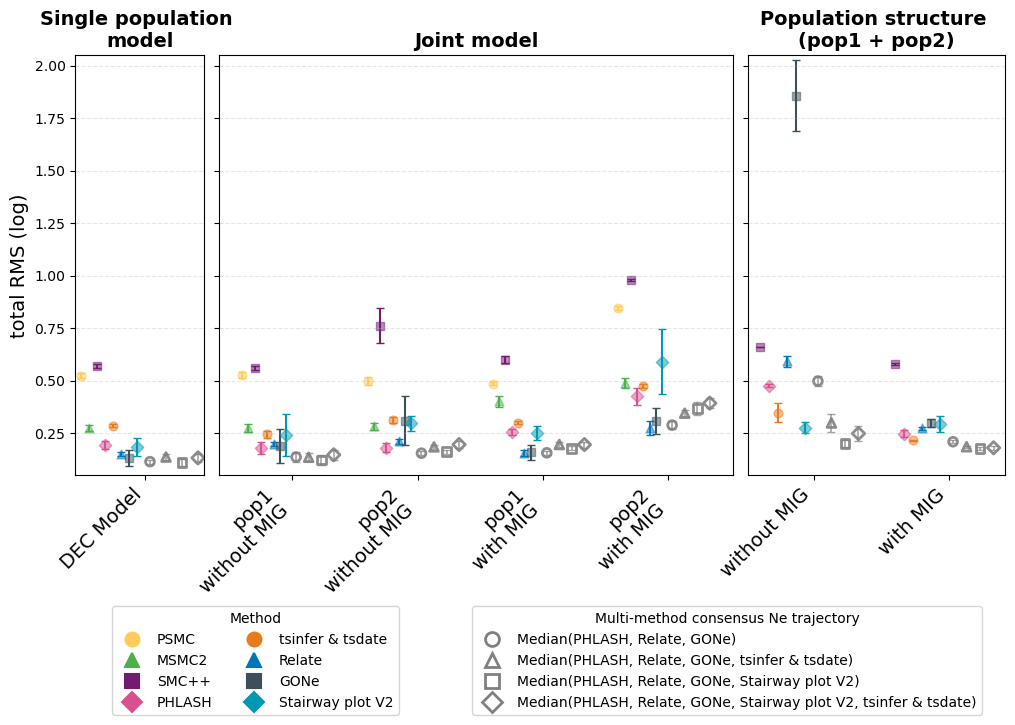

In [638]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D

# Rename map
rename_map = {
    'PHLASH_Relate_GONe': 'Median(PHLASH, Relate, GONe)',
    'PHLASH_Relate_GONe_tsinfer & tsdate': 'Median(PHLASH, Relate, GONe, tsinfer & tsdate)',
    'PHLASH_Relate_GONe_Stairway plot V2': 'Median(PHLASH, Relate, GONe, Stairway plot V2)',
    'PHLASH_Relate_GONe_Stairway plot V2_tsinfer & tsdate': 'Median(PHLASH, Relate, GONe, Stairway plot V2, tsinfer & tsdate)',
    '1': 'pop1',
    '2': 'pop2', 
    'CON SPLIT Model (Pop Structure)': 'without MIG',
    'CON SPLIT MIG Model (Pop Structure)': 'with MIG',
    'DEC SPLIT Model (Pop Structure)': 'without MIG',
    'DEC SPLIT MIG Model (Pop Structure)': 'with MIG',
    'CON SPLIT Model': 'without MIG',
    'CON SPLIT MIG Model': 'with MIG',
    'DEC SPLIT Model': 'without MIG',
    'DEC SPLIT MIG Model': 'with MIG'
}

# Colors for methods
color = {
    'PSMC': '#FFCB5B', 'MSMC2': '#4DAF4A', 'SMC++': '#731A73',
    'PHLASH': '#D65190', 'tsinfer & tsdate': '#E87B1E', 'Relate': '#0076B9', 
    'GONe': '#3D505A', 'Stairway plot V2': '#0098B2',
    'Median(PHLASH, Relate, GONe)': 'grey',
    'Median(PHLASH, Relate, GONe, tsinfer & tsdate)': 'grey',
    'Median(PHLASH, Relate, GONe, Stairway plot V2)': 'grey',
    'Median(PHLASH, Relate, GONe, Stairway plot V2, tsinfer & tsdate)': 'grey',
}

# Filled methods (实心) vs Hollow methods (空心)
filled_methods = ['PSMC', 'MSMC2', 'SMC++', 'PHLASH', 'tsinfer & tsdate', 'Relate', 'GONe', 'Stairway plot V2']
hollow_methods = ['Median(PHLASH, Relate, GONe)', 'Median(PHLASH, Relate, GONe, tsinfer & tsdate)',
                  'Median(PHLASH, Relate, GONe, Stairway plot V2)', 
                  'Median(PHLASH, Relate, GONe, Stairway plot V2, tsinfer & tsdate)']

# Markers for populations
markers = {    'PSMC': 'o', 'MSMC2': '^', 'SMC++': 's',
    'PHLASH': 'D', 'tsinfer & tsdate': 'o', 'Relate':'^', 
    'GONe': 's', 'Stairway plot V2': 'D',
    'Median(PHLASH, Relate, GONe)': 'o',
    'Median(PHLASH, Relate, GONe, tsinfer & tsdate)': '^',
    'Median(PHLASH, Relate, GONe, Stairway plot V2)': 's',
    'Median(PHLASH, Relate, GONe, Stairway plot V2, tsinfer & tsdate)': 'D',}


group1 = ['DEC Model']
group2 = [ 'DEC SPLIT Model', 'DEC SPLIT MIG Model']
group3 = ['DEC SPLIT Model (Pop Structure)', 'DEC SPLIT MIG Model (Pop Structure)']
# Create a copy and apply renames
df_plot = df_median_Ne.copy()
df_plot['method'] = df_plot['method'].replace(rename_map)
df_plot['model_pop'] = df_plot['model'].replace(rename_map)
df_plot['population'] = df_plot['population'].replace(rename_map)

# Split data by group
df_g1 = df_plot[df_plot['model'].isin(group1)]
df_g2 = df_plot[df_plot['model'].isin(group2)]
df_g2['model_pop'] =  df_g2['population'] + '\n' + df_g2['model_pop']

# For g3, filter original group3 models before renaming
df_g3 =  df_plot[df_plot['model'].isin(group3)]

# Helper function to plot
def plot_with_markers(ax, df, color_dict, marker_dict, title,err_col='sd_total_rmse'):
    models = df['model_pop'].unique()
    methods = [m for m in color_dict.keys() if m in df['method'].unique()]
    for i, method in enumerate(methods):
        df_method = df[df['method'] == method]
        for j, model in enumerate(models):
            df_sub = df_method[df_method['model_pop'] == model]
            # Calculate x position with dodge
            # Filled (实心) vs Hollow (空心)
            if method in filled_methods:
                x = j-0.4 + i * 0.4/(len(methods)-4)
                ax.errorbar(x, df_sub['mean_total_rmse'],
                             yerr=df_sub[err_col],
                             fmt='none', ecolor=color_dict[method],
                             elinewidth=1.5, capsize=3, alpha=1, zorder=1)
                ax.scatter(x, df_sub['mean_total_rmse'], 
                            marker=marker_dict[method], 
                            facecolors=color_dict[method],  # 填充颜色
                            edgecolors=color_dict[method],  # 边框颜色
                            s=40, alpha=0.5, linewidths=1)
            else:  # hollow
                x = j+0.03 + (i-len(methods)+4) * 0.4/4
                ax.errorbar(x, df_sub['mean_total_rmse'],
                             yerr=df_sub[err_col],
                             fmt='none', ecolor=color_dict[method],
                             elinewidth=1.2, capsize=3, alpha=0.7, zorder=1)
                ax.scatter(x, df_sub['mean_total_rmse'], 
                            marker=marker_dict[method], 
                            facecolors='none',              # 空心 - 无填充
                            edgecolors=color_dict[method],  # 只有边框颜色
                            s=40, alpha=0.9, linewidths=2)
    
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right',fontsize=14)
    ax.set_title(title, fontsize=14, fontweight='bold')
    # ax.set_yscale('log')
    ax.set_ylim(ax.set_ylim([5e-2, 2.05]) )
    ax.grid(axis='y', alpha=0.3, linestyle='--')


# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True, 
                          gridspec_kw={'width_ratios': [1, 4, 2], 'height_ratios':[3,1],'wspace': 0.05})
for ax in axes[1, :]:
    ax.set_visible(False)

plot_with_markers(axes[0,0], df_g1, color, markers, 'Single population \nmodel')
axes[0,0].set_ylabel('total RMS (log)', fontsize=14)

plot_with_markers(axes[0,1], df_g2, color, markers, 'Joint model')
plot_with_markers(axes[0,2], df_g3, color, markers, 'Population structure \n(pop1 + pop2)')
# After plotting, create legend handles manually
method_handles1 = []

# Filled methods (实心)
for m in filled_methods:
    if m in df_plot['method'].unique():
        method_handles1.append(Line2D([0], [0], marker=markers[m], linestyle='None',
                                      markerfacecolor=color[m], markeredgecolor=color[m],
                                      markersize=10, label=m, markeredgewidth=1.5))

method_handles2 = []
# Hollow methods (空心)
for m in hollow_methods:
    if m in df_plot['method'].unique():
        method_handles2.append(Line2D([0], [0], marker=markers[m], linestyle='None',
                                      markerfacecolor='none', markeredgecolor=color[m],
                                      markersize=10, label=m, markeredgewidth=2))
# Or for figure-level legend
fig.legend(handles=method_handles1, title='Method', bbox_to_anchor=(0.15, 0.2), loc='upper left',ncol=2)
fig.legend(handles=method_handles2, title='Multi-method consensus Ne trajectory', bbox_to_anchor=(0.45, 0.2), loc='upper left')
plt.savefig("../Figure_10_replicates/total_rmse_dec.png", dpi=150)


In [639]:
def plot_with_markers(ax, df, color_dict, marker_dict, title,err_col='sd_total_rmse'):
    models = df['model_pop'].unique()
    methods = [m for m in color_dict.keys() if m in df['method'].unique()]
    for i, method in enumerate(methods):
        df_method = df[df['method'] == method]
        for j, model in enumerate(models):
            df_sub = df_method[df_method['model_pop'] == model]
            # Calculate x position with dodge
            # Filled (实心) vs Hollow (空心)
            if method in filled_methods:
                x = j-0.4 + i * 0.4/(len(methods)-4)
                ax.errorbar(x, df_sub['mean_total_rmse'],
                             yerr=df_sub[err_col],
                             fmt='none', ecolor=color_dict[method],
                             elinewidth=1.5, capsize=3, alpha=1, zorder=1)
                ax.scatter(x, df_sub['mean_total_rmse'], 
                            marker=marker_dict[method], 
                            facecolors=color_dict[method],  # 填充颜色
                            edgecolors=color_dict[method],  # 边框颜色
                            s=40, alpha=0.5, linewidths=1)
            else:  # hollow
                x = j+0.03 + (i-len(methods)+4) * 0.4/4
                ax.errorbar(x, df_sub['mean_total_rmse'],
                             yerr=df_sub[err_col],
                             fmt='none', ecolor=color_dict[method],
                             elinewidth=1.2, capsize=3, alpha=0.7, zorder=1)
                ax.scatter(x, df_sub['mean_total_rmse'], 
                            marker=marker_dict[method], 
                            facecolors='none',              # 空心 - 无填充
                            edgecolors=color_dict[method],  # 只有边框颜色
                            s=40, alpha=0.9, linewidths=2)
    
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right',fontsize=14)
    ax.set_title(title, fontsize=14, fontweight='bold')
    # ax.set_yscale('log')
    ax.set_ylim(ax.set_ylim([-0.05, 2.2]) )
    ax.grid(axis='y', alpha=0.3, linestyle='--')


/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_65190/956717725.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_g2['model_pop'] =  df_g2['population'] + '\n' + df_g2['model_pop']


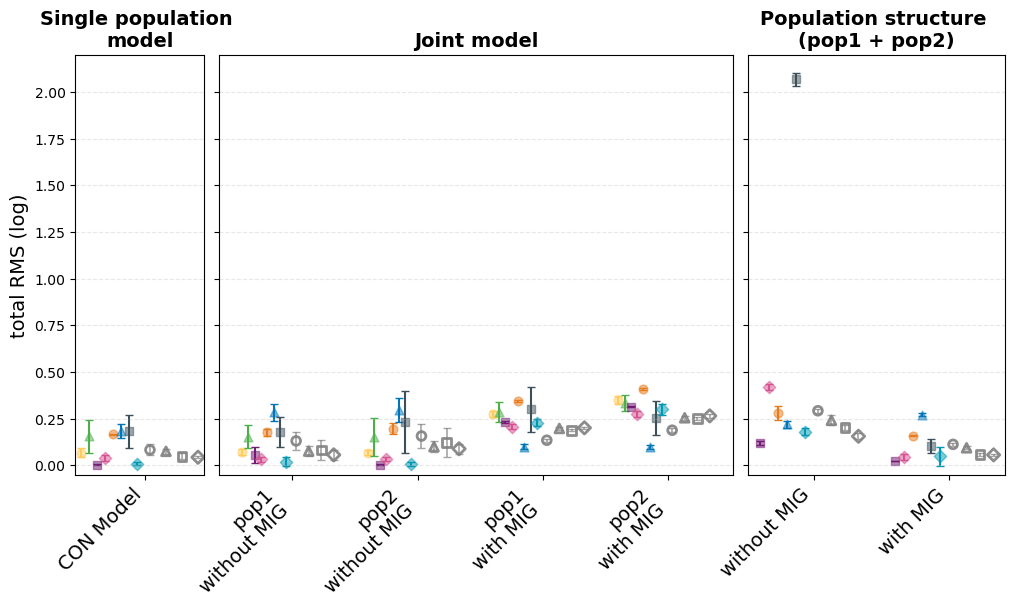

In [640]:
group1 = ['CON Model']
group2 = ['CON SPLIT Model', 'CON SPLIT MIG Model']
group3 = ['CON SPLIT Model (Pop Structure)', 'CON SPLIT MIG Model (Pop Structure)']

# Create a copy and apply renames
df_plot = df_median_Ne.copy()
df_plot['method'] = df_plot['method'].replace(rename_map)
df_plot['model_pop'] = df_plot['model'].replace(rename_map)
df_plot['population'] = df_plot['population'].replace(rename_map)

# Split data by group
df_g1 = df_plot[df_plot['model'].isin(group1)]
df_g2 = df_plot[df_plot['model'].isin(group2)]
df_g2['model_pop'] =  df_g2['population'] + '\n' + df_g2['model_pop']

# For g3, filter original group3 models before renaming
df_g3 =  df_plot[df_plot['model'].isin(group3)]
# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharey=True, 
                          gridspec_kw={'width_ratios': [1, 4, 2], 'height_ratios':[3,1],'wspace': 0.05})
for ax in axes[1, :]:
    ax.set_visible(False)

plot_with_markers(axes[0,0], df_g1, color, markers, 'Single population \nmodel')
axes[0,0].set_ylabel('total RMS (log)', fontsize=14)

plot_with_markers(axes[0,1], df_g2, color, markers, 'Joint model')
plot_with_markers(axes[0,2], df_g3, color, markers, 'Population structure \n(pop1 + pop2)')
# After plotting, create legend handles manually
method_handles1 = []

# Filled methods (实心)
for m in filled_methods:
    if m in df_plot['method'].unique():
        method_handles1.append(Line2D([0], [0], marker=markers[m], linestyle='None',
                                      markerfacecolor=color[m], markeredgecolor=color[m],
                                      markersize=10, label=m, markeredgewidth=1.5))

method_handles2 = []
# Hollow methods (空心)
for m in hollow_methods:
    if m in df_plot['method'].unique():
        method_handles2.append(Line2D([0], [0], marker=markers[m], linestyle='None',
                                      markerfacecolor='none', markeredgecolor=color[m],
                                      markersize=10, label=m, markeredgewidth=2))
plt.savefig("../Figure_10_replicates/total_rmse_con.png", dpi=150)

In [642]:
import numpy as np
# df = pd.read_csv("../data02/rmse_results_0_20_500_2500_20000_200000.csv",index_col="Unnamed: 0")
# df = df.loc[np.r_[0:16, 120:184], :]
df = pd.read_csv("../data02/replicates_rmse_results_0_20_500_2500_20000_200000.csv",index_col="Unnamed: 0")
df = df.loc[(df["genome length"]=="80MB") & (df["sample size"]==100),:]

In [643]:
df['method'].unique()

array(['PSMC', 'MSMC2', 'SMC++', 'PHLASH', 'tsinfer & tsdate', 'Relate',
       'GONe', 'Stairway plot V2'], dtype=object)

In [644]:
df[['[0, 20)', '[20, 500)', '[500, 2500)', '[2500, 20,000)', '>20,000']] = df['mean_time_series_rmse'].apply(
    lambda x: pd.Series(x.strip("[").strip("]").split(","))
)
df[['sd_[0, 20)', 'sd_[20, 500)', 'sd_[500, 2500)', 'sd_[2500, 20,000)', 'sd_>20,000']] = df['sd_time_series_rmse'].apply(
    lambda x: pd.Series(x.strip("[").strip("]").split(","))
)

In [645]:

def fun_rename(x):
    if x["model"] == "CON SPLIT Model" or x["model"] == 'CON SPLIT MIG Model' or x["model"] == 'DEC SPLIT MIG Model' or x["model"] == "DEC SPLIT Model":
        return x["model"] + " (pop"+x["population"]+")"
    else:
        return x["model"]
    
df["model name"] = df.apply(fun_rename,axis=1)

In [646]:
np.unique(df["model name"])

array(['CON Model', 'CON SPLIT MIG Model (pop1)',
       'CON SPLIT MIG Model (pop2)', 'CON SPLIT Model (pop1)',
       'CON SPLIT Model (pop2)', 'DEC Model',
       'DEC SPLIT MIG Model (pop1)', 'DEC SPLIT MIG Model (pop2)',
       'DEC SPLIT Model (pop1)', 'DEC SPLIT Model (pop2)'], dtype=object)

In [647]:
df.loc[df["method"]=="GONe",["[500, 2500)","[2500, 20,000)", ">20,000"]]= "nan"
df.loc[df["method"]=="GONe",["sd_[500, 2500)","sd_[2500, 20,000)", "sd_>20,000"]]= "nan"

In [648]:
np.unique(df["method"])

array(['GONe', 'MSMC2', 'PHLASH', 'PSMC', 'Relate', 'SMC++',
       'Stairway plot V2', 'tsinfer & tsdate'], dtype=object)

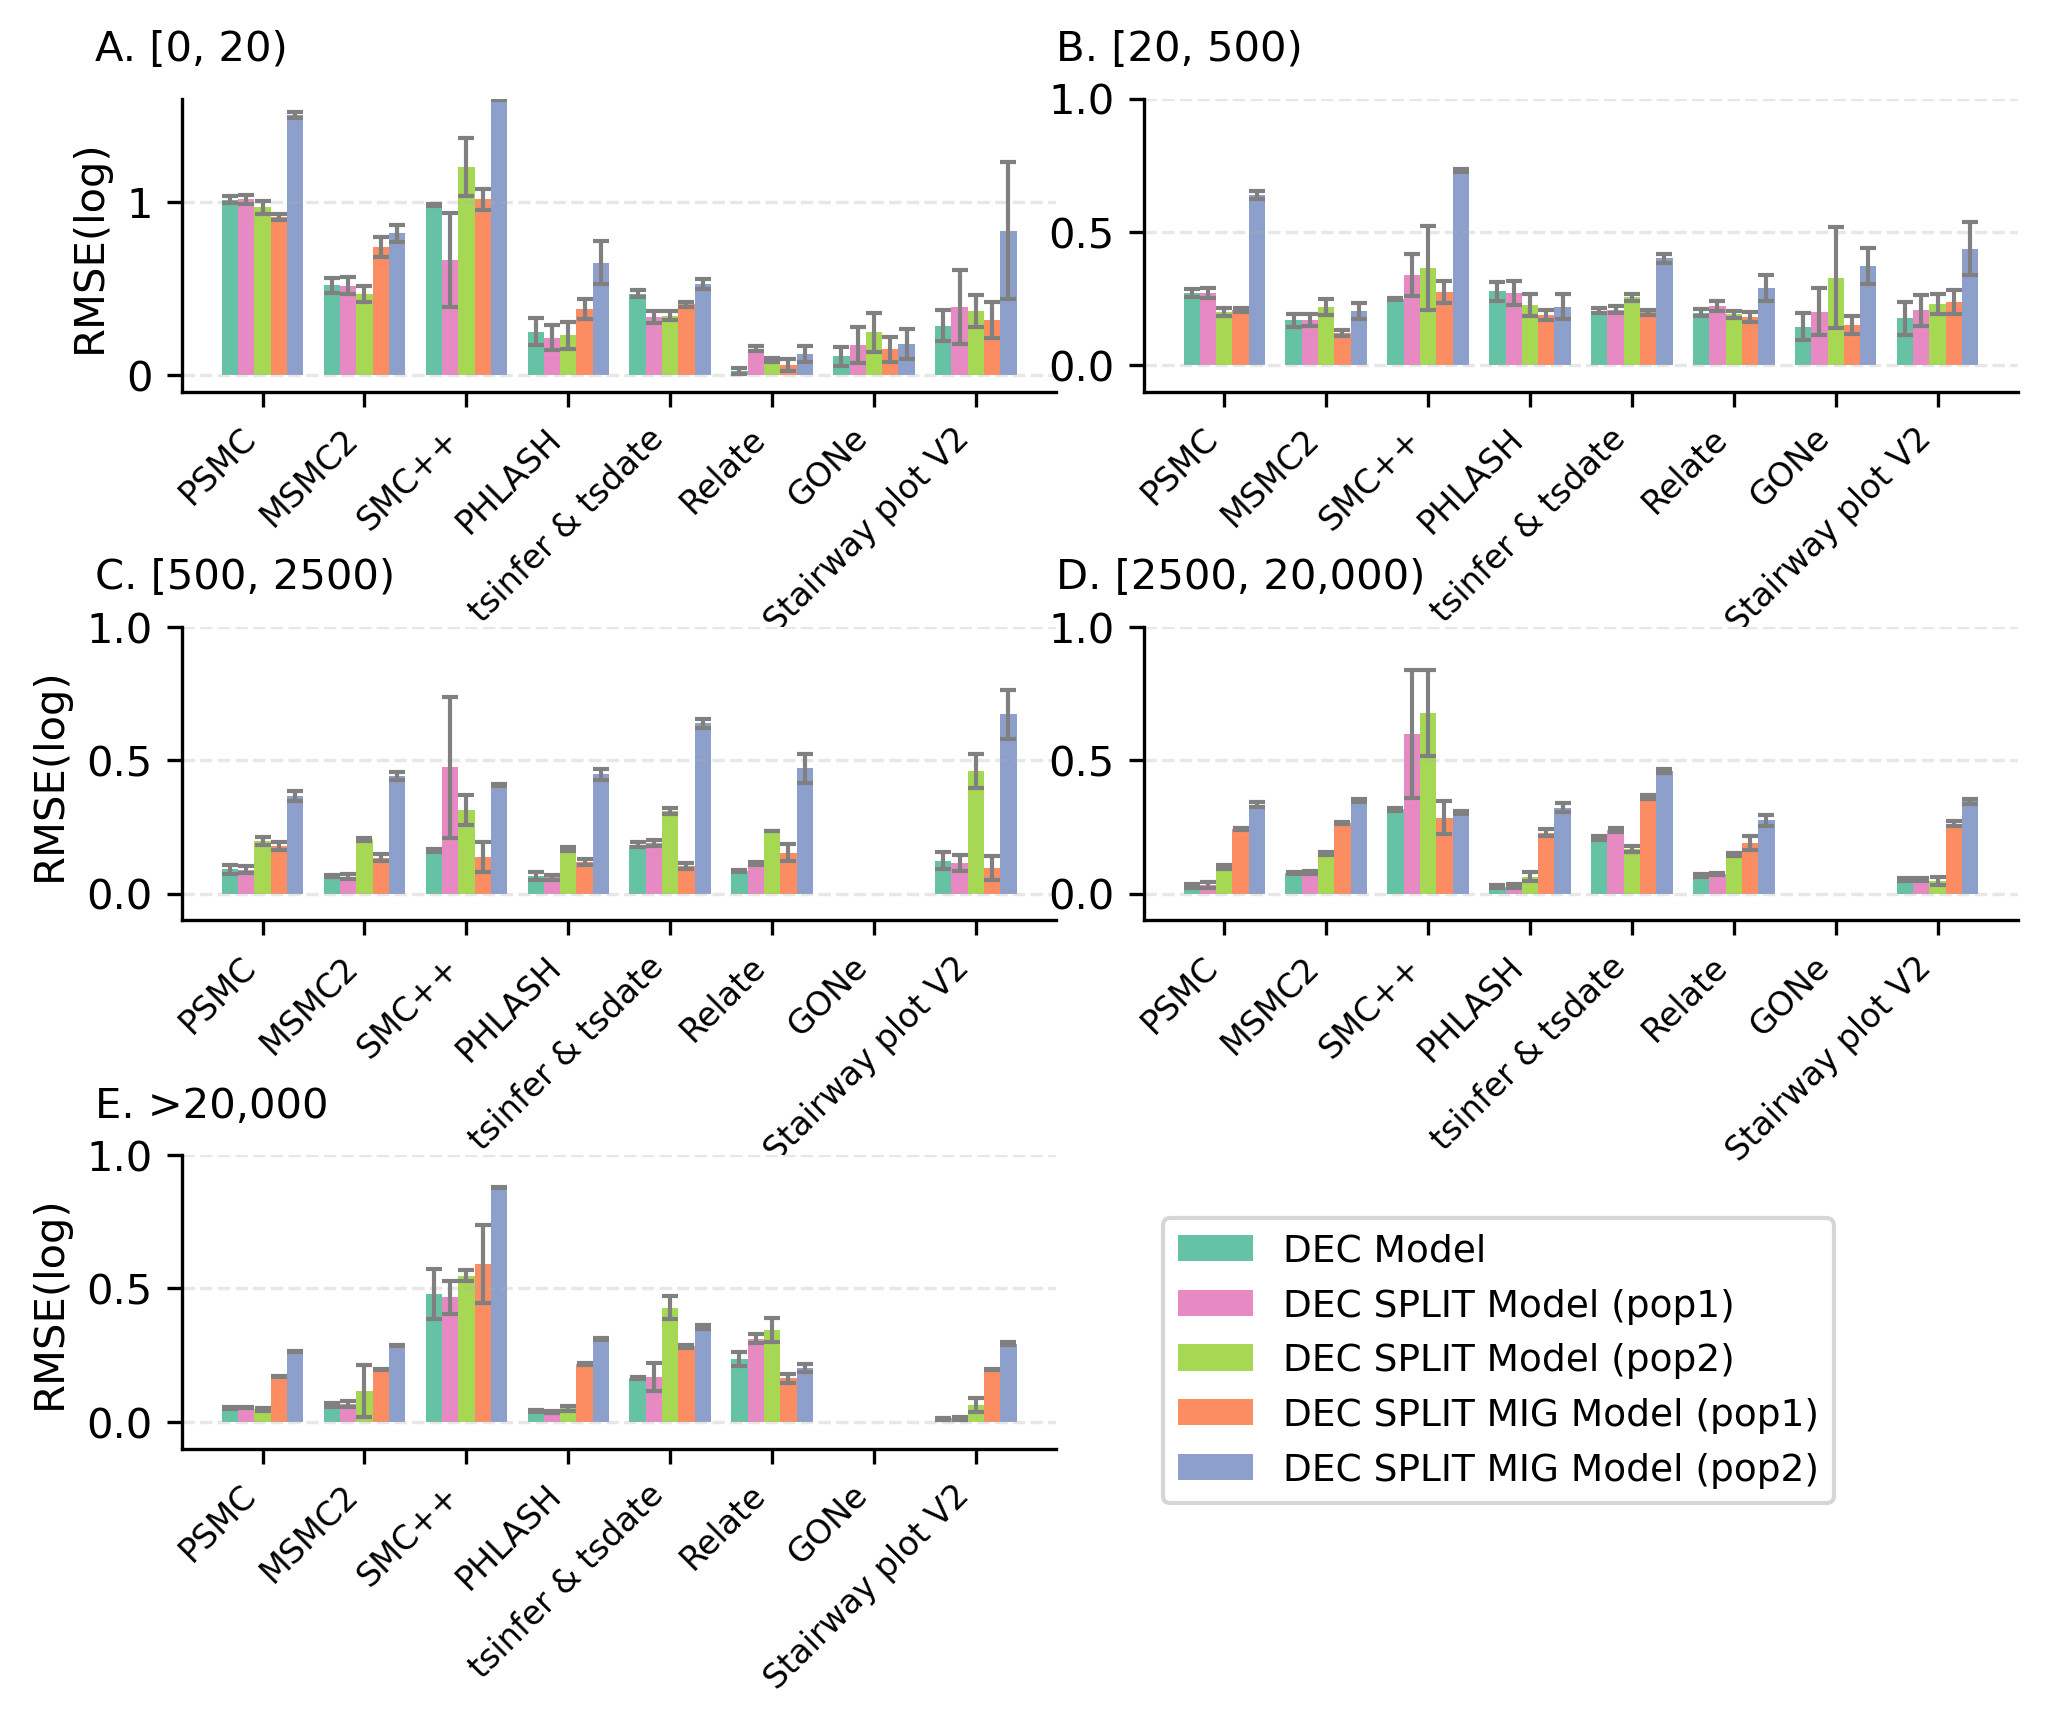

In [649]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from brokenaxes import brokenaxes
import matplotlib.gridspec as gridspec
fig, axes = plt.subplots(3, 2, figsize=(7.2, 6),dpi=300)
axes = axes.flatten()
seaborn_colors = sns.color_palette("Set2", 5)
# Colors matching the original chart
colors = {
    'DEC Model': seaborn_colors[0],
    'DEC SPLIT MIG Model (pop1)': seaborn_colors[1],
    'DEC SPLIT MIG Model (pop2)': seaborn_colors[2],
    'DEC SPLIT Model (pop1)': seaborn_colors[3],
    'DEC SPLIT Model (pop2)': seaborn_colors[4],
    # 'DEC Model with MIG (Pop Structure)': seaborn_colors[5],
    # 'DEC Model with SPLIT (Pop Structure)': seaborn_colors[6]
}

# Bar width and positions
methods = [ "PSMC", "MSMC2", "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
models =['DEC Model',
        'DEC SPLIT Model (pop1)', 'DEC SPLIT Model (pop2)',
        'DEC SPLIT MIG Model (pop1)', 'DEC SPLIT MIG Model (pop2)',
    ]

period_columns = ['[0, 20)', '[20, 500)', '[500, 2500)', '[2500, 20,000)', '>20,000']
subplot_letter=["A","B","C","D","E"]
# Bar width and positions
n_methods = len(methods)
n_models = len(models)
bar_width = 0.8 / n_models  # Adjust bar width based on number of models
x = np.arange(n_methods)

# Plot each period
for idx, (ax, period_col) in enumerate(zip(axes, period_columns)):

    # Get all unique methods across all models
    x_pos = np.arange(len(methods))
    
    # Plot bars for each model
    for i, model in enumerate(models):
        model_data = df[df['model name'] == model]
        # Build values array, using 0 for missing method-model combinations
        values = []
        sds = []
        for method in methods:
            method_row = model_data[model_data['method'] == method]
            value = method_row[period_col].values[0]
            sd = method_row[f"sd_{period_col}"].values[0]
            if "nan" in value:
                value = 0
                sd = np.nan
            else:
                value = float(value)
                sd = float(sd)
            sds.append(sd)
            values.append(value)
        offset = (i - n_models/2 + 0.5) * bar_width
        ax.bar(x_pos + offset, values, bar_width, label=model,
            color=colors.get(model, '#333333'))
        ax.errorbar(x_pos + offset, values, yerr=sds, 
            fmt='none',           # 不画额外的点，只画误差棒
            ecolor='grey',       # 误差棒颜色
            capsize=2,            # 两端横杠的长度
            capthick=1,         # 两端横杠的粗细
            elinewidth=1,       # 中间竖线的粗细
            zorder=3)             # 保证误差棒画在柱子上层，不被遮挡
    
    # Customize subplot
    ax.text(-0.1, 1.1, subplot_letter[idx]+". "+period_col, 
        transform=ax.transAxes,
        fontsize=10, 
        verticalalignment='bottom',
        horizontalalignment='left')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(methods, fontsize=8, rotation=45, ha='right')
    if idx ==1 or idx==3:
        pass
        # ax.yaxis.set_visible(False) 
        # ax.spines['left'].set_visible(False) 
    else:
        ax.set_ylabel('RMSE(log)', fontsize=10)
    # ax.set_yscale('log')
    if idx == 0:
        ax.set_ylim(-0.1, 1.6)
    else:
        ax.set_ylim(-0.1, 1)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    if idx == 4:
        ax.legend(loc='center left', bbox_to_anchor=(1.1, 0.3),  fontsize=9, ncol=1)

axes[5].axis('off')
plt.subplots_adjust(
    left=0.1,      # left
    right=0.95,    # right
    top=0.90,      # top
    bottom=0.15,    # botton
    hspace=0.8,    # Vertical 
    wspace=0.1     # Horizon 
)
# plt.tight_layout()
plt.show()
fig.savefig("../Figure_10_replicates/rmse_dec.png")

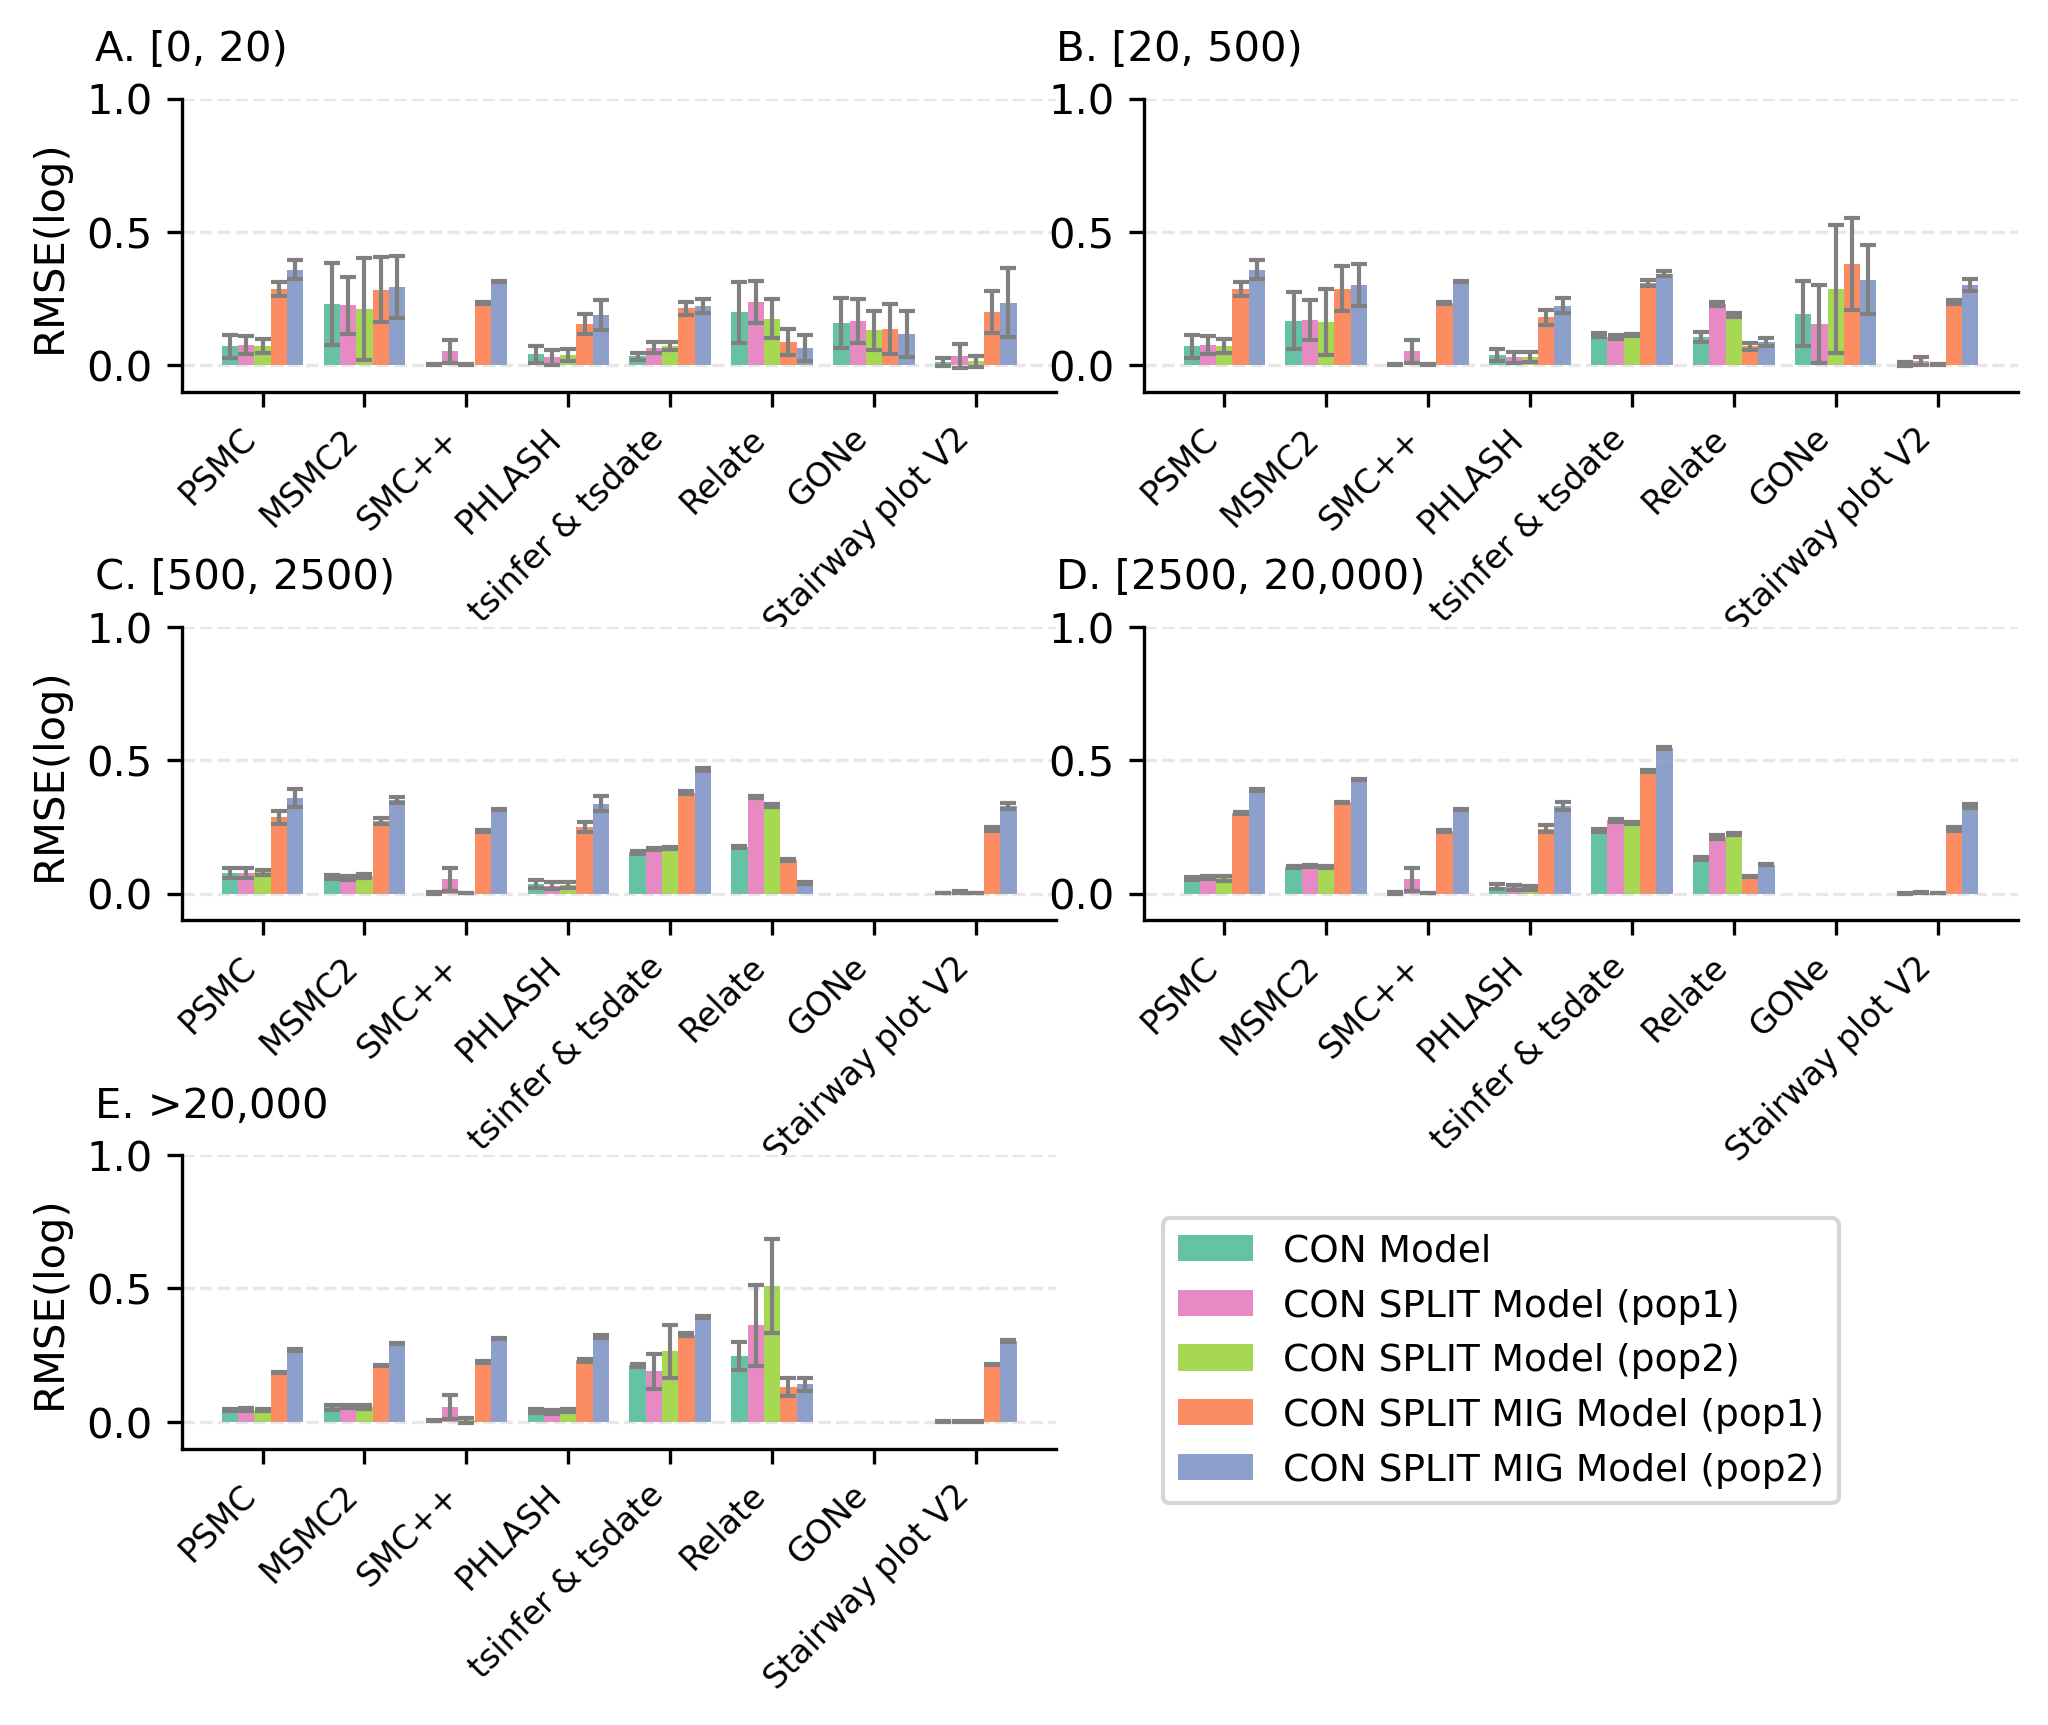

In [650]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from brokenaxes import brokenaxes
import matplotlib.gridspec as gridspec
fig, axes = plt.subplots(3, 2, figsize=(7.2, 6),dpi=300)
axes = axes.flatten()
seaborn_colors = sns.color_palette("Set2", 5)
# Colors matching the original chart
colors = {
    'CON Model': seaborn_colors[0],
    'CON SPLIT MIG Model (pop1)': seaborn_colors[1],
    'CON SPLIT MIG Model (pop2)': seaborn_colors[2],
    'CON SPLIT Model (pop1)': seaborn_colors[3],
    'CON SPLIT Model (pop2)': seaborn_colors[4],
    # 'DEC Model with MIG (Pop Structure)': seaborn_colors[5],
    # 'DEC Model with SPLIT (Pop Structure)': seaborn_colors[6]
}

# Bar width and positions
methods = [ "PSMC", "MSMC2", "SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
models =['CON Model',
        'CON SPLIT Model (pop1)', 'CON SPLIT Model (pop2)',
        'CON SPLIT MIG Model (pop1)', 'CON SPLIT MIG Model (pop2)',
    ]

period_columns = ['[0, 20)', '[20, 500)', '[500, 2500)', '[2500, 20,000)', '>20,000']
subplot_letter=["A","B","C","D","E"]
# Bar width and positions
n_methods = len(methods)
n_models = len(models)
bar_width = 0.8 / n_models  # Adjust bar width based on number of models
x = np.arange(n_methods)

# Plot each period
for idx, (ax, period_col) in enumerate(zip(axes, period_columns)):

    # Get all unique methods across all models
    x_pos = np.arange(len(methods))
    
    # Plot bars for each model
    for i, model in enumerate(models):
        model_data = df[df['model name'] == model]
        # Build values array, using 0 for missing method-model combinations
        values = []
        sds = []
        for method in methods:
            method_row = model_data[model_data['method'] == method]
            value = method_row[period_col].values[0]
            sd = method_row[f"sd_{period_col}"].values[0]
            if "nan" in value:
                value = 0
                sd = np.nan
            else:
                value = float(value)
                sd = float(sd)
            sds.append(sd)
            values.append(value)
        offset = (i - n_models/2 + 0.5) * bar_width
        ax.bar(x_pos + offset, values, bar_width, label=model,
            color=colors.get(model, '#333333'))
        ax.errorbar(x_pos + offset, values, yerr=sds, 
            fmt='none',           # 不画额外的点，只画误差棒
            ecolor='grey',       # 误差棒颜色
            capsize=2,            # 两端横杠的长度
            capthick=1,         # 两端横杠的粗细
            elinewidth=1,       # 中间竖线的粗细
            zorder=3)             # 保证误差棒画在柱子上层，不被遮挡
    
    # Customize subplot
    ax.text(-0.1, 1.1, subplot_letter[idx]+". "+period_col, 
        transform=ax.transAxes,
        fontsize=10, 
        verticalalignment='bottom',
        horizontalalignment='left')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(methods, fontsize=8, rotation=45, ha='right')
    if idx ==1 or idx==3:
        pass
        # ax.yaxis.set_visible(False) 
        # ax.spines['left'].set_visible(False) 
    else:
        ax.set_ylabel('RMSE(log)', fontsize=10)
    # ax.set_yscale('log')

    ax.set_ylim(-0.1, 1)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    if idx == 4:
        ax.legend(loc='center left', bbox_to_anchor=(1.1, 0.3),  fontsize=9, ncol=1)

axes[5].axis('off')
plt.subplots_adjust(
    left=0.1,      # left
    right=0.95,    # right
    top=0.90,      # top
    bottom=0.15,    # botton
    hspace=0.8,    # Vertical 
    wspace=0.1     # Horizon 
)
# plt.tight_layout()
plt.show()
fig.savefig("../Figure_10_replicates/rmse_con.png")

# 

# sample size 

In [651]:
df = pd.read_csv("../data02/replicates_rmse_results_0_20_500_2500_20000_200000.csv",index_col="Unnamed: 0")
df = df.loc[(df["model"]=="CON Model") | (df["model"]=="DEC Model"),:]
df = df.loc[(df["method"]!="PSMC") & (df["method"]!="MSMC2"),:]
df = df.loc[(df["genome length"]=="80MB"),:]

In [652]:
def plot_by_sample_size(ax, df, color_dict,markers, methods, sample_sizes, title, 
                         err_col='sd_total_rmse', mean_col='mean_total_rmse', sample_col='sample size'):
    n = len(sample_sizes)
    width = 0.8  # 每个 method 分组占据的总宽度
    for i, method in enumerate(methods):
        df_method = df[df['method'] == method]
        for j, ss in enumerate(sample_sizes):
            df_sub = df_method[df_method[sample_col] == int(ss)]
            if df_sub.empty:
                continue
            # 在 method 分组内，按 sample size 做 dodge
            x = i - width/2 + (j + 0.5) * width/n
            ax.scatter(x, df_sub[mean_col],marker=markers[ss],color=color_dict[ss],alpha=0.5,s=60)
            ax.errorbar(x, df_sub[mean_col], yerr=df_sub[err_col],
                        fmt='none', color=color_dict[ss], 
                        capsize=3, elinewidth=1.3, alpha=1, zorder=2)

    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods, rotation=25, ha='center', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, linestyle='--')

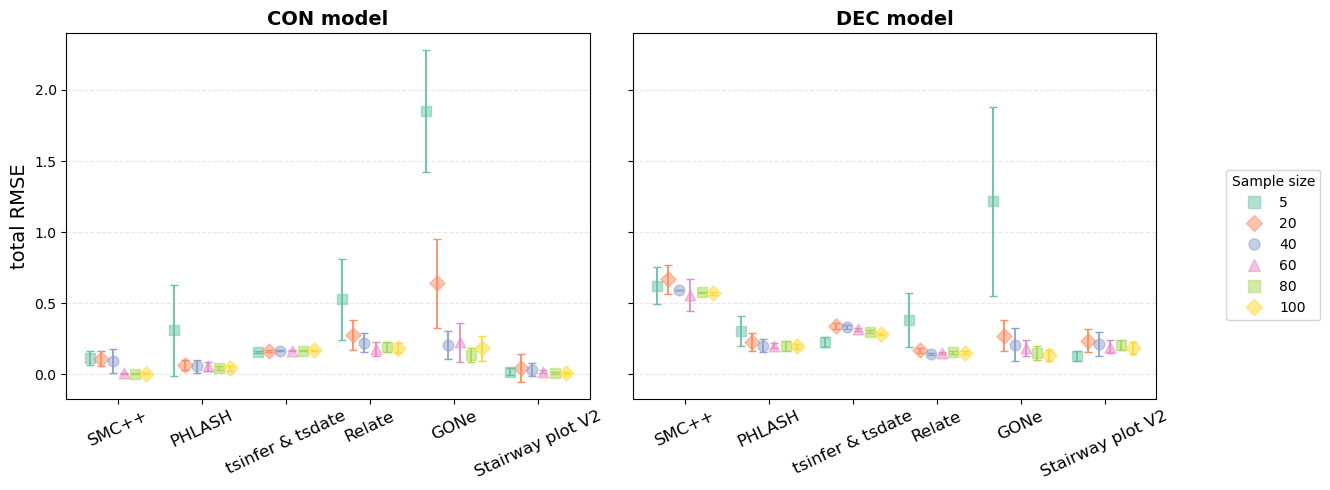

In [653]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
seaborn_colors = sns.color_palette("Set2", 6)
# Colors matching the original chart
colors = {
    "5": seaborn_colors[0],
    "20": seaborn_colors[1],
    "40": seaborn_colors[2],
    "60": seaborn_colors[3],
    "80": seaborn_colors[4],
    "100": seaborn_colors[5],
}
# Bar width and positions
methods = ["SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
sample_sizes =["5","20","40","60","80","100"]
# Rename map
rename_map = {
    'PHLASH_Relate_GONe': 'Median(PHLASH, Relate, GONe)',
    'PHLASH_Relate_GONe_tsinfer & tsdate': 'Median(PHLASH, Relate, GONe, tsinfer & tsdate)',
    'PHLASH_Relate_GONe_Stairway plot V2': 'Median(PHLASH, Relate, GONe, Stairway plot V2)',
    'PHLASH_Relate_GONe_Stairway plot V2_tsinfer & tsdate': 'Median(PHLASH, Relate, GONe, Stairway plot V2, tsinfer & tsdate)',
    '1': 'pop1',
    '2': 'pop2', 
    'CON SPLIT Model (Pop Structure)': 'without MIG',
    'CON SPLIT MIG Model (Pop Structure)': 'with MIG',
    'DEC SPLIT Model (Pop Structure)': 'without MIG',
    'DEC SPLIT MIG Model (Pop Structure)': 'with MIG',
    'CON SPLIT Model': 'without MIG',
    'CON SPLIT MIG Model': 'with MIG',
    'DEC SPLIT Model': 'without MIG',
    'DEC SPLIT MIG Model': 'with MIG'
}
# Markers for populations
markers = { '5': 's',
    '20': 'D', '40': 'o', '60':'^', 
    '80': 's', '100': 'D'}


group1 = ['CON Model']
group2 = [ 'DEC Model']
# Create a copy and apply renames
df_plot = df.copy()
df_plot['method'] = df_plot['method'].replace(rename_map)
df_plot['model_pop'] = df_plot['model'].replace(rename_map)
df_plot['population'] = df_plot['population'].replace(rename_map)

# Split data by group
df_g1 = df_plot[df_plot['model'].isin(group1)]
df_g2 = df_plot[df_plot['model'].isin(group2)]


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

plot_by_sample_size(axes[0], df_g1, colors,markers, methods, sample_sizes, 'CON model')
axes[0].set_ylabel('total RMSE', fontsize=14)

plot_by_sample_size(axes[1], df_g2, colors,markers, methods, sample_sizes, 'DEC model')

# 图例：按 sample size 上色
legend_handles = [
    Line2D([0], [0], marker=markers[ss], linestyle='None', 
           markerfacecolor=colors[ss], markeredgecolor=colors[ss], 
           markersize=8, label=ss,alpha=0.5)
    for ss in sample_sizes
]
fig.legend(handles=legend_handles, title='Sample size', 
           bbox_to_anchor=(1.02, 0.5), loc='center left')

plt.tight_layout()
fig.savefig("../Figure_10_replicates/rmse_sample_size.png")

In [502]:
df = pd.read_csv("../data02/replicates_rmse_results_0_20_500_2000_20000_200000.csv",index_col="Unnamed: 0")
df = df.loc[(df["model"]=="CON Model") | (df["model"]=="DEC Model"),:]
df = df.loc[(df["method"]!="PSMC") & (df["method"]!="MSMC2"),:]
df = df.loc[(df["genome length"]=="80MB"),:]
df[['[0, 20)', '[20, 500)', '[500, 2000)', '[2000, 20,000)', '>20,000']] = df['mean_time_series_rmse'].apply(
    lambda x: pd.Series(x.strip("[").strip("]").split(","))
)
df[['sd_[0, 20)', 'sd_[20, 500)', 'sd_[500, 2000)', 'sd_[2000, 20,000)', 'sd_>20,000']] = df['sd_time_series_rmse'].apply(
    lambda x: pd.Series(x.strip("[").strip("]").split(","))
)
df.loc[df["method"]=="GONe",["[500, 2000)","[2000, 20,000)", ">20,000"]]= "nan"
df.loc[df["method"]=="GONe",["sd_[500, 2000)","sd_[2000, 20,000)", "sd_>20,000"]]= "nan"

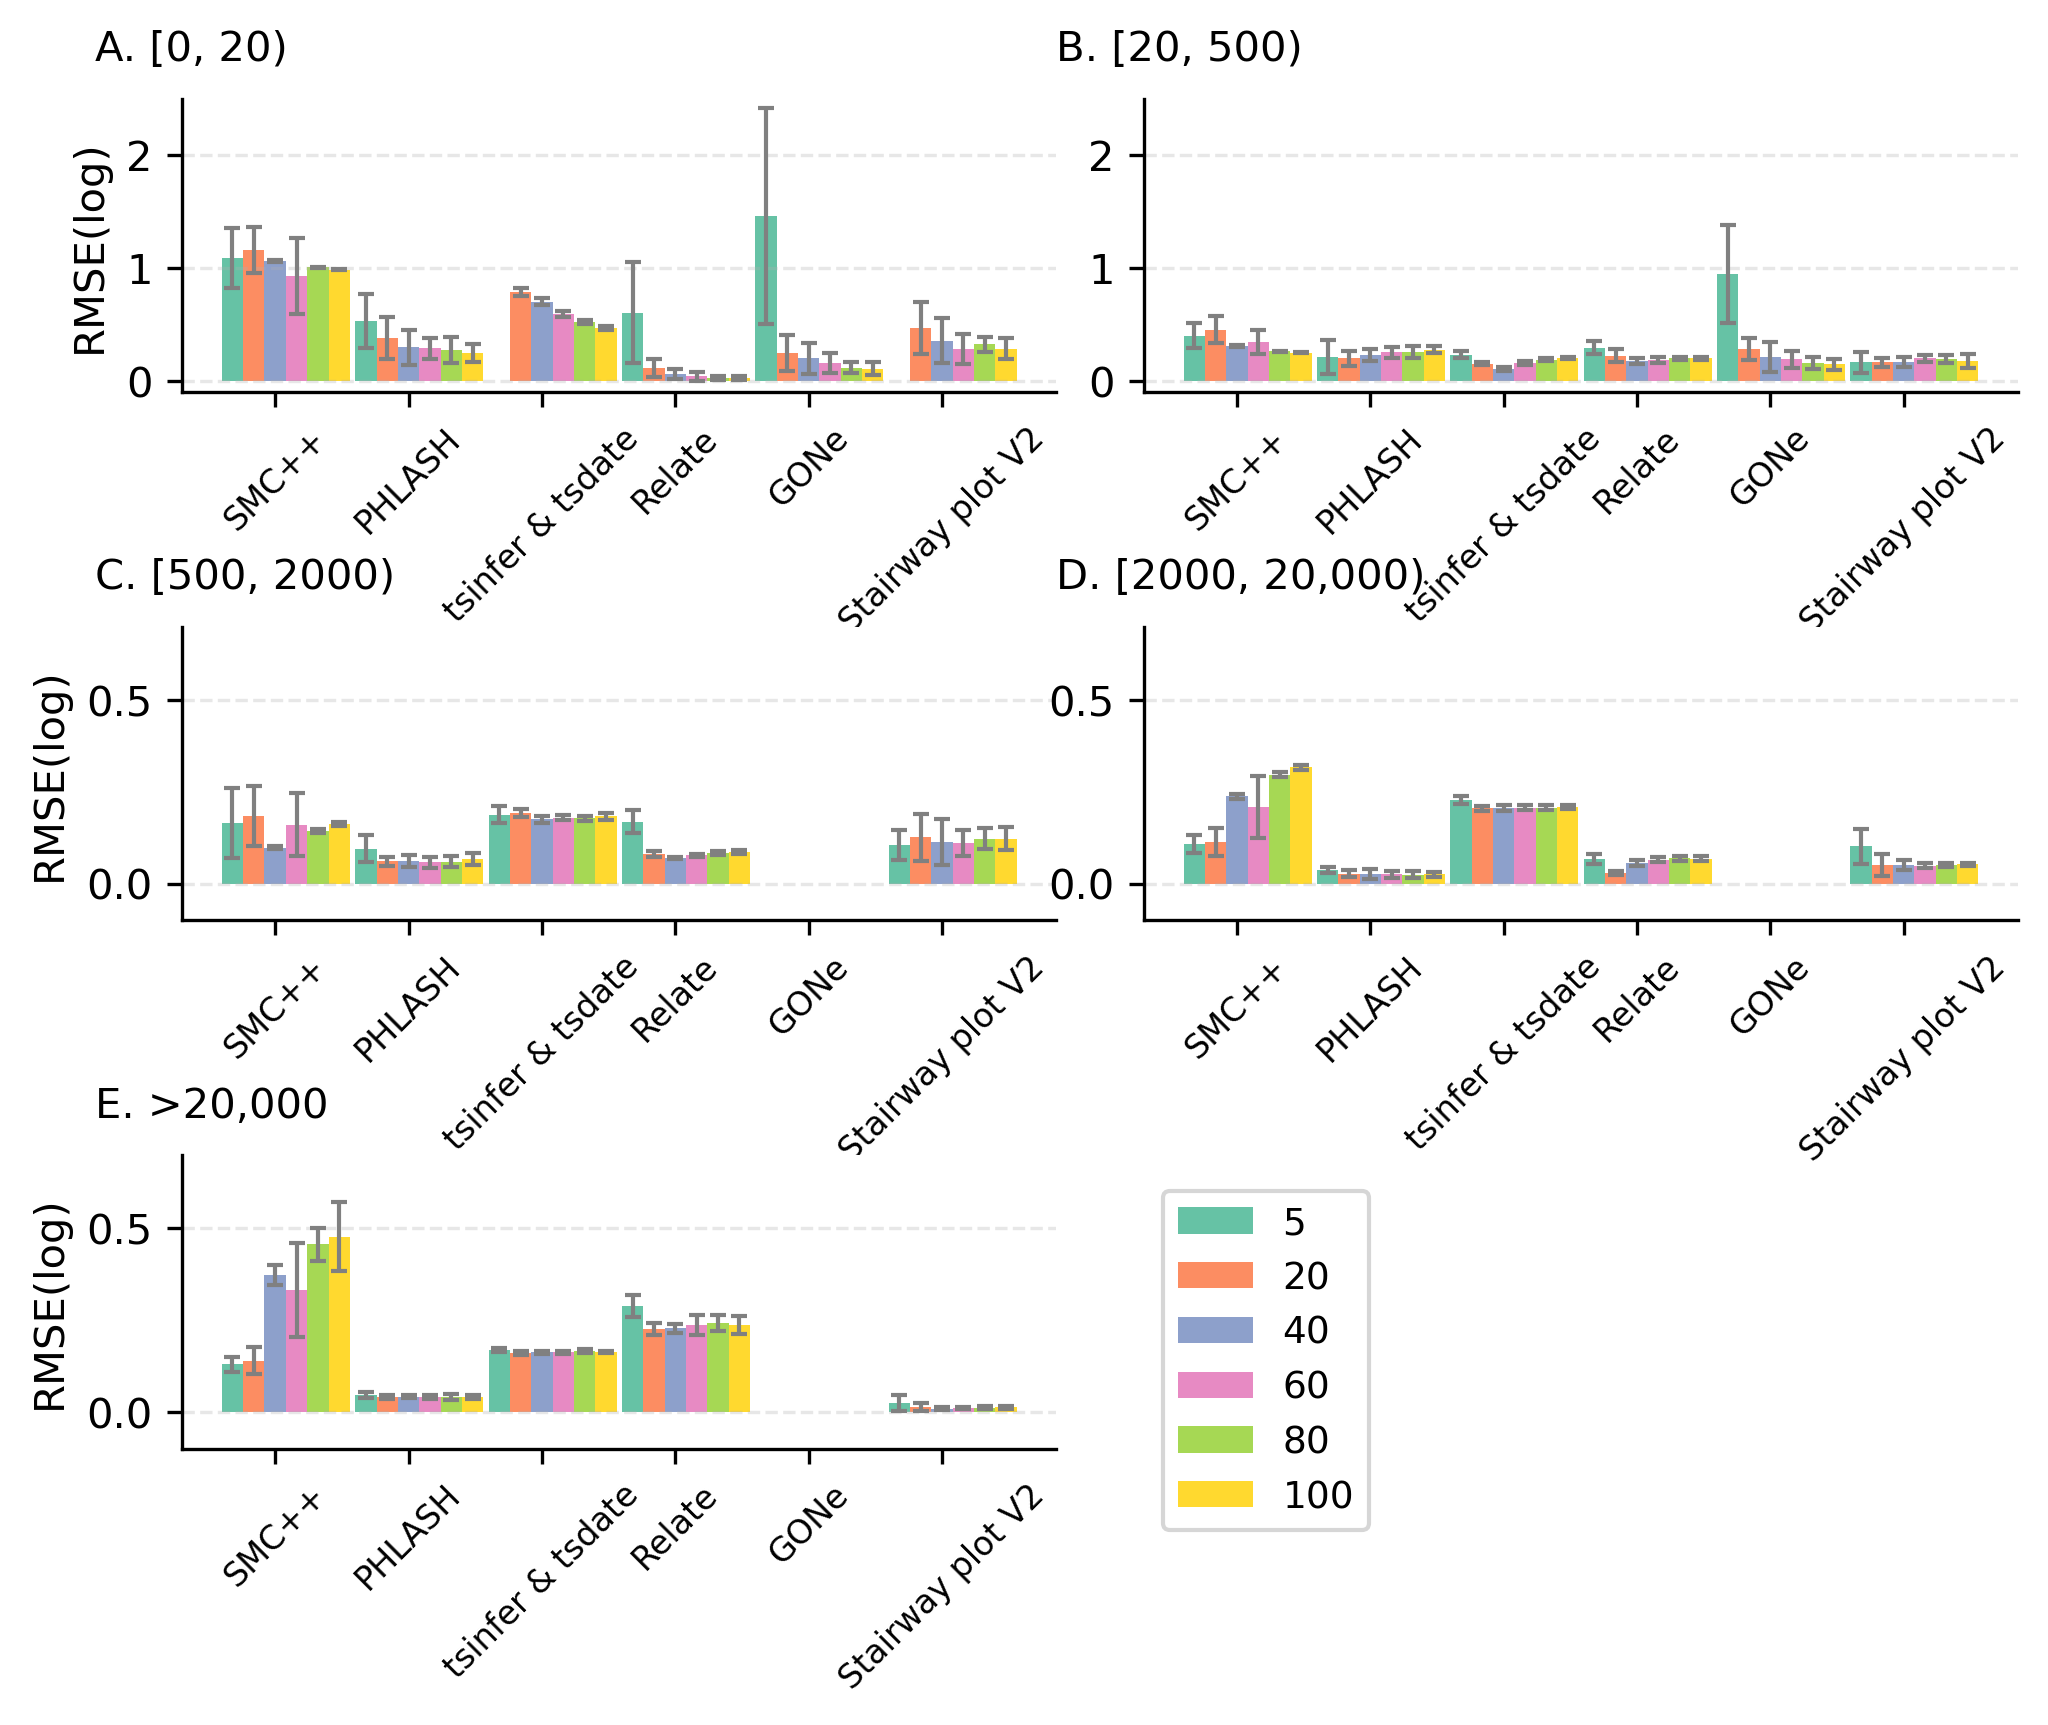

In [504]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from brokenaxes import brokenaxes
import matplotlib.gridspec as gridspec
fig, axes = plt.subplots(3, 2, figsize=(7.2, 6),dpi=300)
axes = axes.flatten()
seaborn_colors = sns.color_palette("Set2", 6)
# Colors matching the original chart
colors = {
    "5": seaborn_colors[0],
    "20": seaborn_colors[1],
    "40": seaborn_colors[2],
    "60": seaborn_colors[3],
    "80": seaborn_colors[4],
    "100": seaborn_colors[5],
}
df = df[df['model'] == "DEC Model"]
# Bar width and positions
methods = ["SMC++", "PHLASH", "tsinfer & tsdate",  "Relate","GONe", "Stairway plot V2"]
sample_sizes =["5","20","40","60","80","100"]

period_columns = ['[0, 20)', '[20, 500)', '[500, 2000)', '[2000, 20,000)', '>20,000']
subplot_letter=["A","B","C","D","E"]
# Bar width and positions
n_methods = len(methods)
n_models = len(models)
bar_width = 0.8 / n_models  # Adjust bar width based on number of models
x = np.arange(n_methods)

# Plot each period
for idx, (ax, period_col) in enumerate(zip(axes, period_columns)):

    # Get all unique methods across all models
    x_pos = np.arange(len(methods))
    
    # Plot bars for each model
    for i, sample_size in enumerate(sample_sizes):
        model_data = df[df['sample size'] == int(sample_size)]
        # Build values array, using 0 for missing method-model combinations
        values = []
        sds = []
        for method in methods:
            method_row = model_data[model_data['method'] == method]
            value = method_row[period_col].values[0]
            sd = method_row[f"sd_{period_col}"].values[0]
            if "nan" in value:
                value = 0
                sd = np.nan
            else:
                value = float(value)
                sd = float(sd)
            sds.append(sd)
            values.append(value)
        offset = (i - n_models/2 + 0.5) * bar_width
        ax.bar(x_pos + offset, values, bar_width, label=sample_size,
            color=colors.get(sample_size , '#333333'))
        ax.errorbar(x_pos + offset, values, yerr=sds, 
            fmt='none',           # 不画额外的点，只画误差棒
            ecolor='grey',       # 误差棒颜色
            capsize=2,            # 两端横杠的长度
            capthick=1,         # 两端横杠的粗细
            elinewidth=1,       # 中间竖线的粗细
            zorder=3)             # 保证误差棒画在柱子上层，不被遮挡
    
    # Customize subplot
    ax.text(-0.1, 1.1, subplot_letter[idx]+". "+period_col, 
        transform=ax.transAxes,
        fontsize=10, 
        verticalalignment='bottom',
        horizontalalignment='left')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(methods, fontsize=8, rotation=45, ha='center')
    if idx ==1 or idx==3:
        pass
        # ax.yaxis.set_visible(False) 
        # ax.spines['left'].set_visible(False) 
    else:
        ax.set_ylabel('RMSE(log)', fontsize=10)
    # ax.set_yscale('log')
    if (idx == 0) or (idx==1):
        ax.set_ylim(-0.1, 2.5)
    else:
        ax.set_ylim(-0.1, 0.7)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    if idx == 4:
        ax.legend(loc='center left', bbox_to_anchor=(1.1, 0.3),  fontsize=9, ncol=1)

axes[5].axis('off')
plt.subplots_adjust(
    left=0.1,      # left
    right=0.95,    # right
    top=0.90,      # top
    bottom=0.15,    # botton
    hspace=0.8,    # Vertical 
    wspace=0.1     # Horizon 
)
# plt.tight_layout()
plt.show()
fig.savefig("../Figure_10_replicates/rmse_dec_sample_size.png")

In [127]:
true_times = [     0,     20,    200,   2000,  20000, 200000]

true_sizes = [ 1000,  5000, 12500, 20000, 25000, 25000]

# combined_times = np.sort(np.unique(np.concatenate([true_times, split_epoch])))
# np.searchsorted(combined_times, true_times)
# np.searchsorted( true_times,combined_times)
# only_split_epoch = np.setdiff1d(split_epoch,true_times)
# for i,m in enumerate(np.searchsorted( true_times,combined_times)):
#     if combined_times[i] in only_split_epoch:
#         print(true_sizes[m-1])
#     else:
#         print(true_sizes[m])
# Combine and get unique sorted times
combined_times = np.sort(np.unique(np.concatenate([true_times, split_epoch])))

# Find which split_epoch values are NOT in true_times
only_split_epoch = np.setdiff1d(split_epoch, true_times)

# Find insertion positions of combined_times in true_times
indices = np.searchsorted(true_times, combined_times)

# Create a boolean mask for split_epoch-only times
is_split_only = np.isin(combined_times, only_split_epoch)

# Adjust indices: use i-1 for split-only times, i for others
adjusted_indices = np.where(is_split_only, indices - 1, indices)

# Get aligned sizes in one operation
aligned_sizes = np.array(true_sizes)[adjusted_indices]


[0 1 2 2 3 4 5]
[ 1000  5000 12500 12500 20000 25000 25000]


In [113]:

combined_times 

array([     0,     20,    200,    400,   2000,  20000, 200000])